**NOT USED — use `preprocess_artifact_removal_by_sqr_deviation.py` (via `run_preprocess.sh`) instead, the current pipeline.**

**NOTE (legacy/reference — superseded by the .py script):** This is the interactive notebook version of `preprocess_artifact_removal_by_sqr_deviation.py` — same squared-deviation artifact detection method, but from before the script was generalised with `argparse` for batch/SLURM use. `base_folder` here is hardcoded to one dataset (GLC6962_g_g0). For any new recording, use the `.py` script via `run_preprocess.sh` instead; keep this notebook only if you want to step through the pipeline interactively cell-by-cell.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# just for this machine
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "2"

In [3]:
from pathlib import Path

In [4]:
import numpy as np
import matplotlib.pyplot as plt
#import torch
import spikeinterface.full as si
import scipy.signal
from tqdm.auto import tqdm, trange

In [5]:
'''
base_folder = Path(r"E:\GLC6644\GLC6644h_g0\\")
spikeglx_folder = base_folder / 'GLC6644h_g0_imec0'

rec_dir = spikeglx_folder #data_dir / "cuttlefish" / "GLC6962_g"
exp_dir = spikeglx_folder / 'kilosort4_cw' #data_dir / "cuttlefish" / "GLC6962_g_res"
'''
# folder where a preprocessed copy of the recording will be saved
# scratch_dir is on a fast SSD on my computer. see the commment
# in the last cell before KS stuff below for more on this.
# ppx_dir = Path(r"E:\scratch\\") / "tmp_preprocessing"

base_folder = "/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0"
spikeglx_folder = os.path.join(base_folder, 'GLC6962_g_g0_imec0')

rec_dir = spikeglx_folder 
#exp_dir = spikeglx_folder / 'kilosort4_cw' / 'kilosort4' / ' '#data_dir / "cuttlefish" / "GLC6962_g_res"

In [6]:
si.set_global_job_kwargs(n_jobs=4)

In [7]:
for meta_filename in Path(spikeglx_folder).glob("*ap.meta"):
    print(meta_filename)

word = 'imSampRate'
with open(meta_filename, 'r') as meta_info:
    # read all lines in a list
    lines = meta_info.readlines()
    for line in lines:
        # check if string present on a current line
        if line.find(word) != -1:
            index = lines.index(line)

line = lines[index]
fs = line[11:]
fs = float(fs)
print(fs)

/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/GLC6962_g_g0_imec0/GLC6962_g_g0_t0.imec0.ap.meta
30000.0


## Preprocessing

In [8]:
rec = si.read_spikeglx(spikeglx_folder, stream_name='imec0.ap', load_sync_channel=False)#si.read_spikeglx(base_folder)
rec.get_probe().to_dataframe()
rec

SpikeGLXRecordingExtractor: 384 channels - 30.0kHz - 1 segments - 80,418,082 samples 
                            2,680.60s (44.68 minutes) - int16 dtype - 57.52 GiB

In [9]:
# this is setup for visualization
n_seconds = rec.get_duration()
n_mins = n_seconds / 60
chlen = 512
t_start = rec.get_start_time()
min_start = int(np.ceil(t_start / 60))

Created folder /nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/raw_neural_data for saving images
1577554


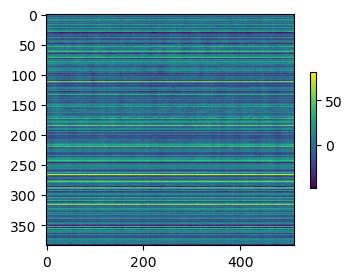

10577554


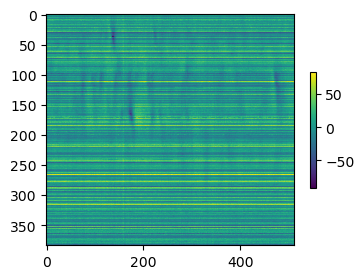

19577554


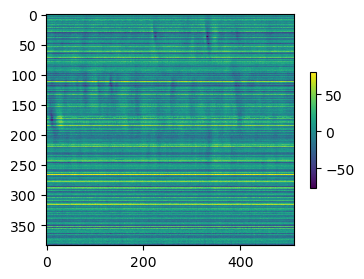

28577554


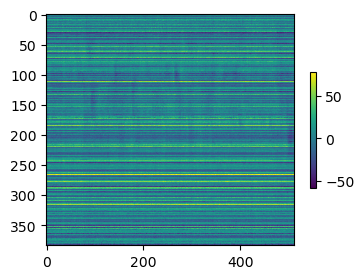

37577554


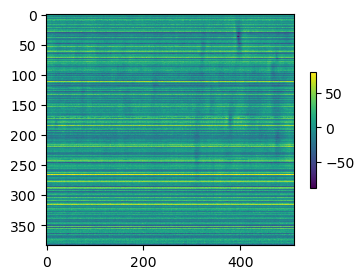

46577554


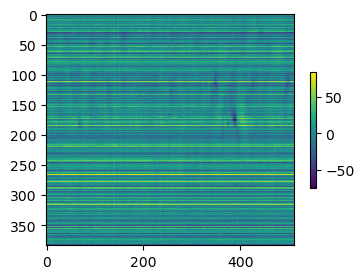

55577554


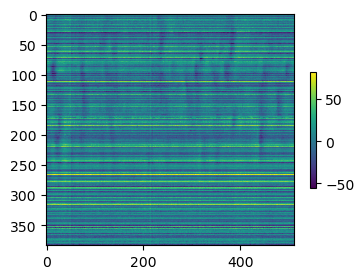

64577554


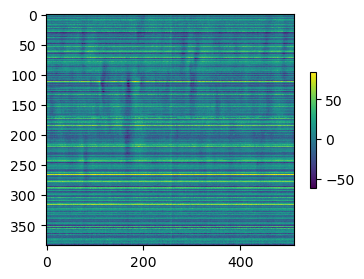

73577554


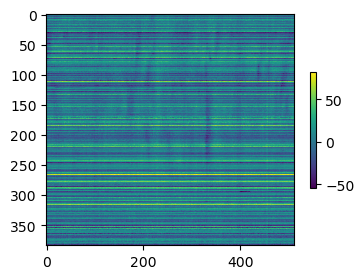

all plots successfully saved


In [10]:
save_folder = os.path.join(base_folder, "raw_neural_data")

if not os.path.exists(save_folder) or len(os.listdir(save_folder)) == 0:
    os.makedirs(save_folder, exist_ok=True)
    print(f"Created folder {save_folder} for saving images")
    imkw = dict(aspect='auto', interpolation='none')
    for min_start in range(min_start, min_start + int(n_mins), 5):
        sample_start = rec.time_to_sample_index(min_start * 60)
        print(sample_start)
        chunk = rec.get_traces(0, sample_start, sample_start + chlen)

        fig, ax = plt.subplots(figsize=(4, 3))
        im = ax.imshow(chunk.T, **imkw)
        plt.colorbar(im, ax=ax, shrink=0.5)

        filename = os.path.join(save_folder, f"{min_start:04d}min.png")
        plt.savefig(filename, bbox_inches = 'tight')
        plt.show()
        plt.close(fig)
    print("all plots successfully saved")
else: 
    print(f"Folder {save_folder} already exists and is not empty. Skip saving images.")

In [11]:
# preprocess
rec0 = si.read_spikeglx(rec_dir, stream_name='imec0.ap', load_sync_channel=False)  # to avoid stacking the ppx chain accidentally.
rec = si.highpass_filter(rec0, dtype="float32")
bc, labels = si.detect_bad_channels(rec, seed=0)
print(f"{bc=}")

bc=array(['imec0.ap#AP191'], dtype='<U64')


In [15]:
rec1 = rec.remove_channels(bc)

In [16]:
rec1

ChannelSliceRecording: 383 channels - 30.0kHz - 1 segments - 80,418,082 samples 
                       2,680.60s (44.68 minutes) - float32 dtype - 114.74 GiB

In [17]:
rec

HighpassFilterRecording: 384 channels - 30.0kHz - 1 segments - 80,418,082 samples 
                         2,680.60s (44.68 minutes) - float32 dtype - 115.04 GiB

In [13]:
chunks = si.get_random_data_chunks(rec,  num_chunks_per_segment=100, seed=0)

In [14]:
std = chunks.std(0)

Channel std plot /u/gongt/GLC6962_g_g0/raw_channel_std.png already exists. Skip saving.


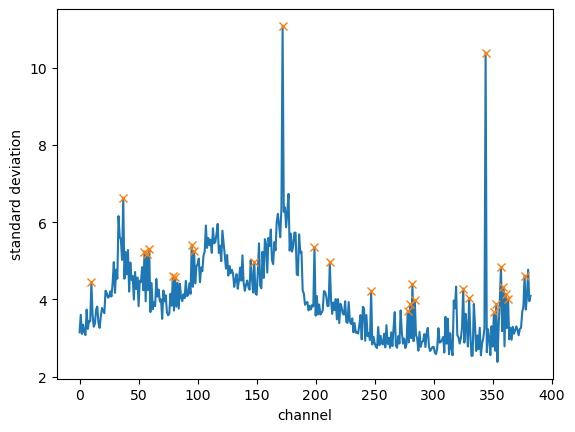

In [15]:
peaks, _ = scipy.signal.find_peaks(std, threshold=0.75)
plt.plot(std)
plt.plot(peaks, std[peaks], "x")
plt.xlabel('channel')
plt.ylabel('standard deviation')

save_path = os.path.join(base_folder, "raw_channel_std.png")
if not os.path.exists(save_path):
    plt.savefig(save_path, bbox_inches = 'tight')
    print(f"Saved channel std plot to {save_path}")
else: 
    print(f"Channel std plot {save_path} already exists. Skip saving.")

plt.show()
plt.close()

In [16]:
rec = rec.remove_channels(rec.channel_ids[peaks])
rec = si.common_reference(rec)

In [17]:

# list_triggers=np.asarray([200.74, 567.52, 570.9, 638.4, 635.23, 683.01, 1184.5, 1184.85, 1470.75, 1476.7, 1482.04, 1485.54, 1508.13, 1869.19, 2167.46, 2435.75, 2639.78])
# list_triggers_samp = list_triggers*fs
# rec_clean = si.remove_artifacts(recording=rec, list_triggers=list_triggers_samp, mode='zeros',ms_before=100,ms_after = 700)


## Extract TTLs

In [18]:
### Extract TTLs ### 
raw_rec = si.read_spikeglx(base_folder, stream_name='nidq', load_sync_channel=False)
raw_rec

SpikeGLXRecordingExtractor: 9 channels - 30002.750562 Hz - 1 segments - 80,424,705 samples 
                            2,680.58s (44.68 minutes) - int16 dtype - 1.35 GiB

In [19]:
ttlName = ['sync','stim','side','overview','hi-res']
input_name = input("Enter a name: ")
chanInterest = ttlName.index(input_name)
chanInterest

3

In [20]:
ttl_sig = raw_rec.get_traces()[:,chanInterest]
norm_sig = (ttl_sig - np.min(ttl_sig)) / (np.max(ttl_sig) - np.min(ttl_sig))
#median_signal = np.median(ttl_sig[ttl_sig > 0])
threshold = 0.5
thresh_signal = (norm_sig >= threshold).astype(int)
diff_sig = np.diff(thresh_signal)

indOn = np.where(diff_sig > 0.6)[0]
indOff = np.where(diff_sig < -0.6)[0]

ttl_on = indOn/fs
ttl_off = indOff/fs

len(ttl_on)

106548

In [21]:
filename = f"ttl_{input_name}_on2.txt"
save_filename = os.path.join(base_folder, filename)
with open(save_filename, "w") as f:
    f.write(",".join(map(str, ttl_on)))

## FIND EINK ARTIFACTS

Total samples: 80418082, analyzing in 60s windows


Scanning dataset by minute:   0%|          | 0/46 [00:00<?, ?it/s]

Processing samples 0 to 1800016
1800016
1800016


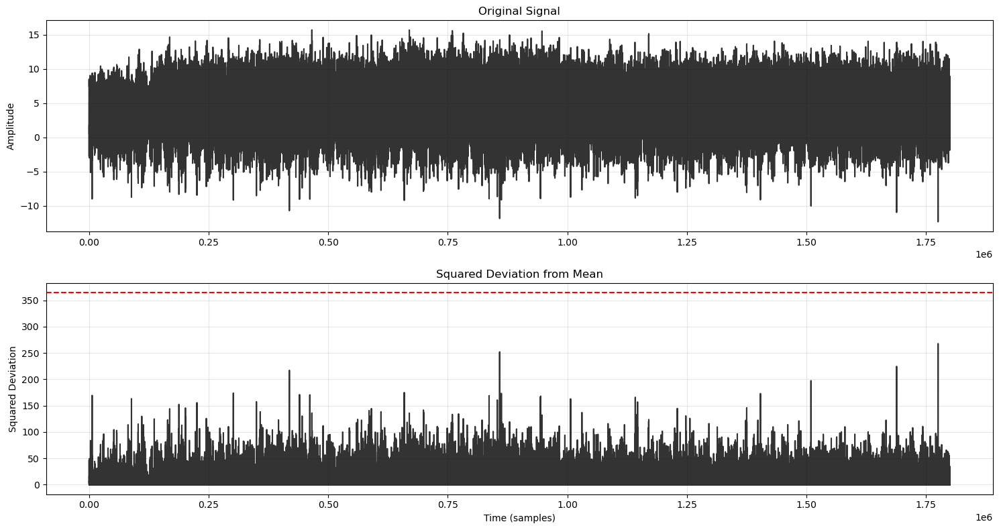

Processing samples 1770016 to 3570032
1800016
1800016


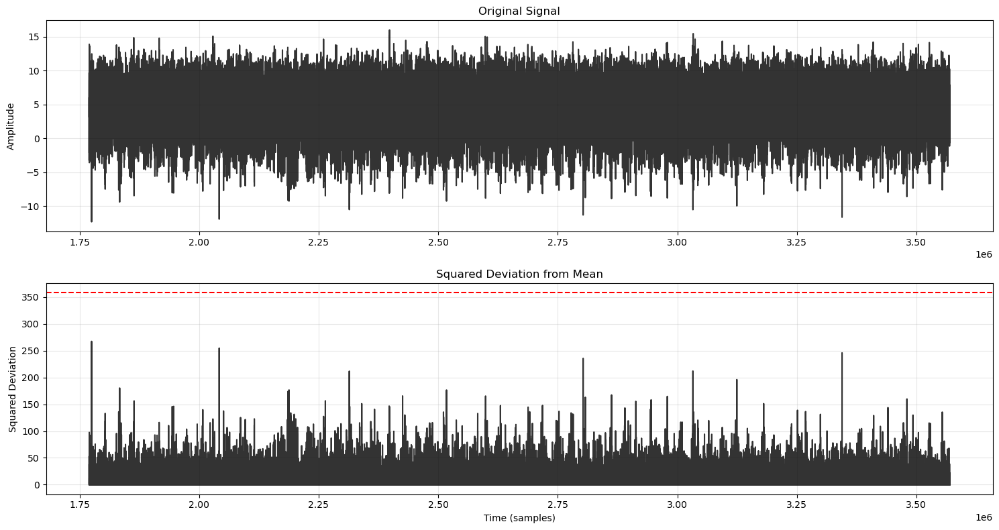

Processing samples 3540032 to 5340048
1800016
1800016
[4184456 4184457]


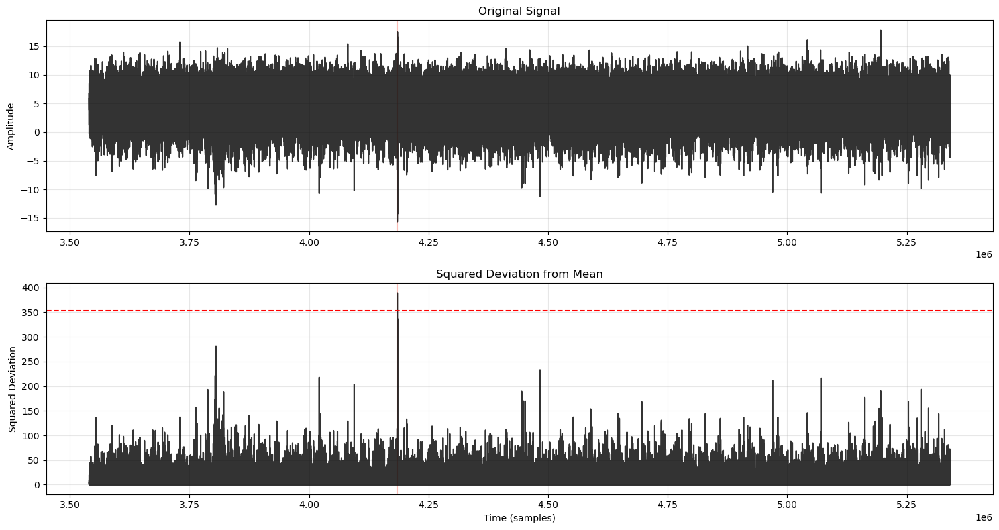

Processing samples 5310048 to 7110064
1800016
1800016


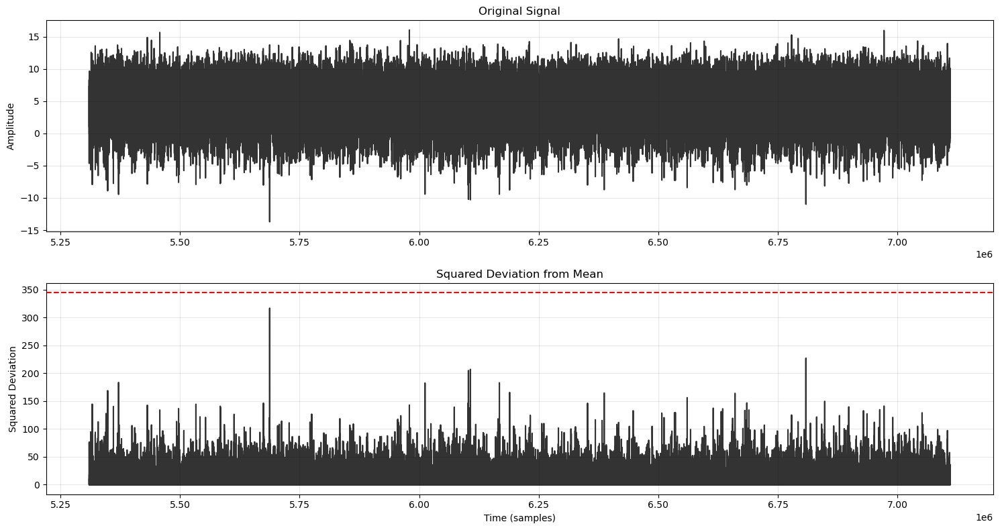

Processing samples 7080064 to 8880080
1800016
1800016
[7308142 7308143]


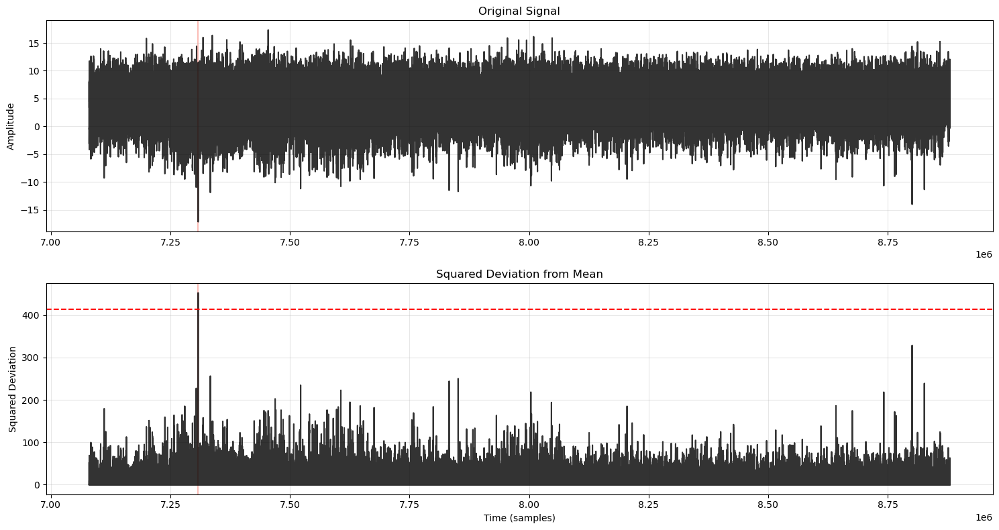

Processing samples 8850080 to 10650096
1800016
1800016


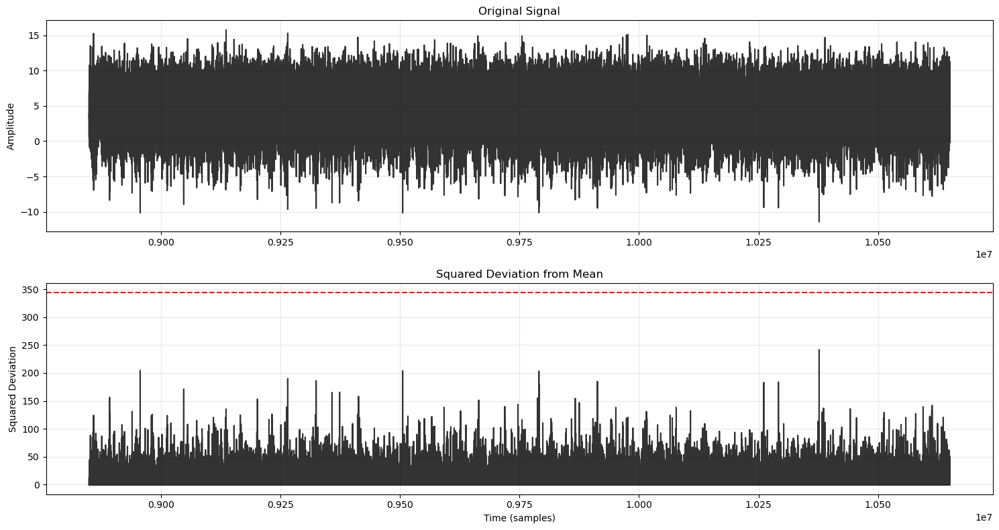

Processing samples 10620096 to 12420112
1800016
1800016
[11765960 11765961 11765962 11765963 11765964 11765965]


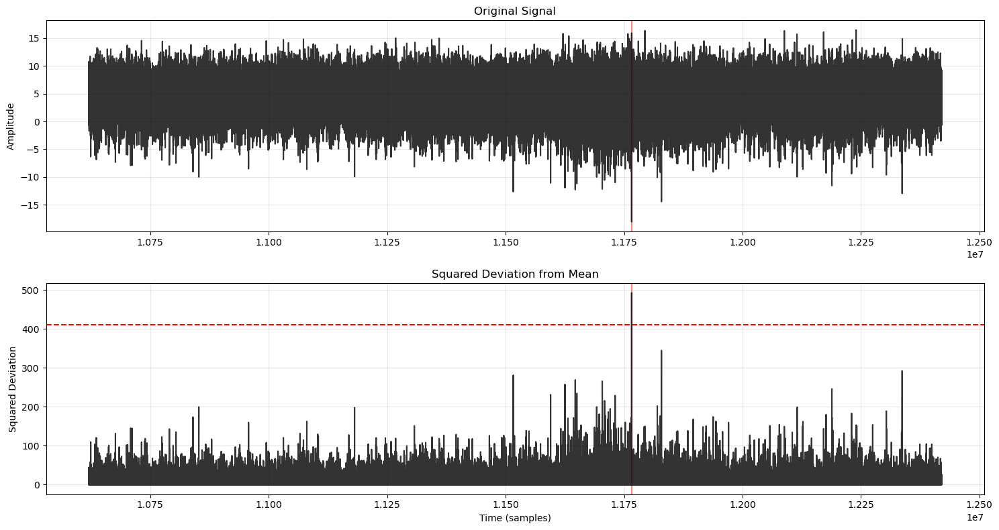

Processing samples 12390112 to 14190128
1800016
1800016


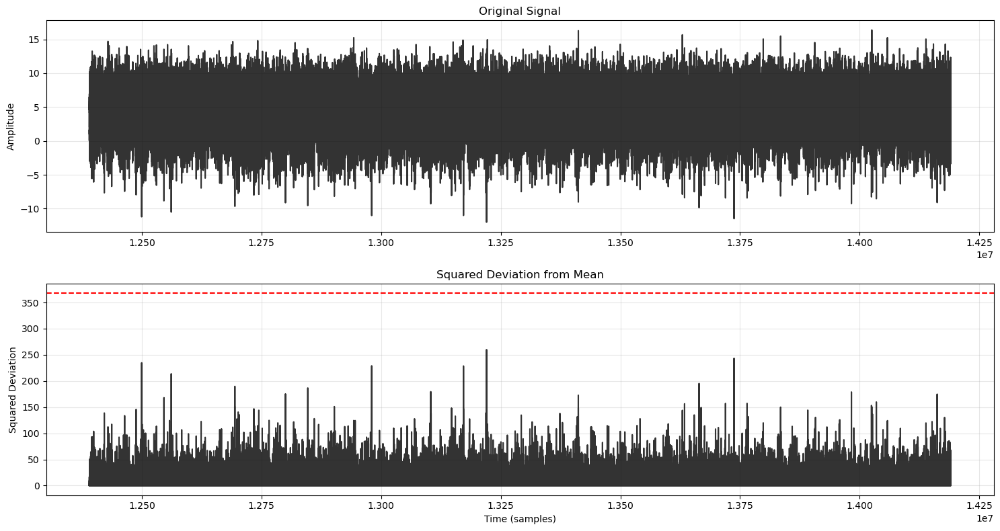

Processing samples 14160128 to 15960144
1800016
1800016


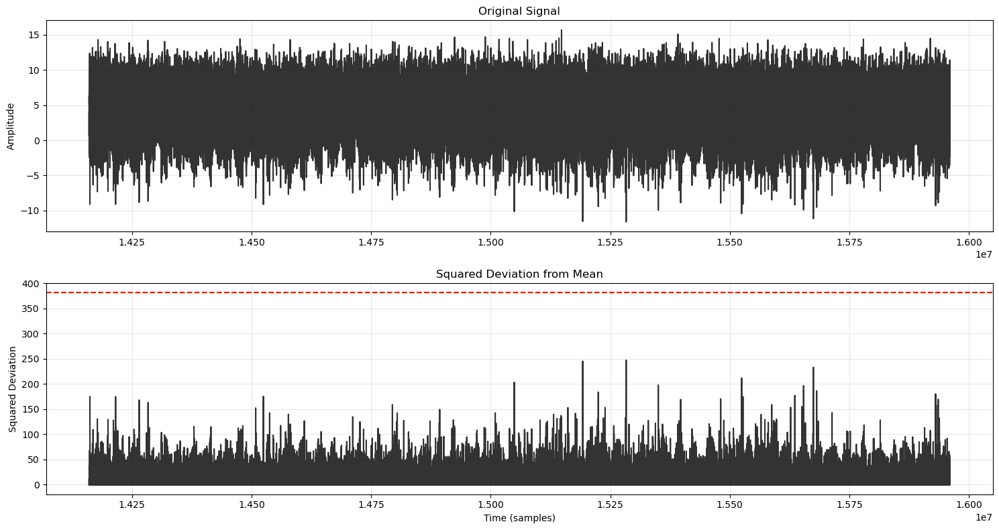

Processing samples 15930144 to 17730160
1800016
1800016


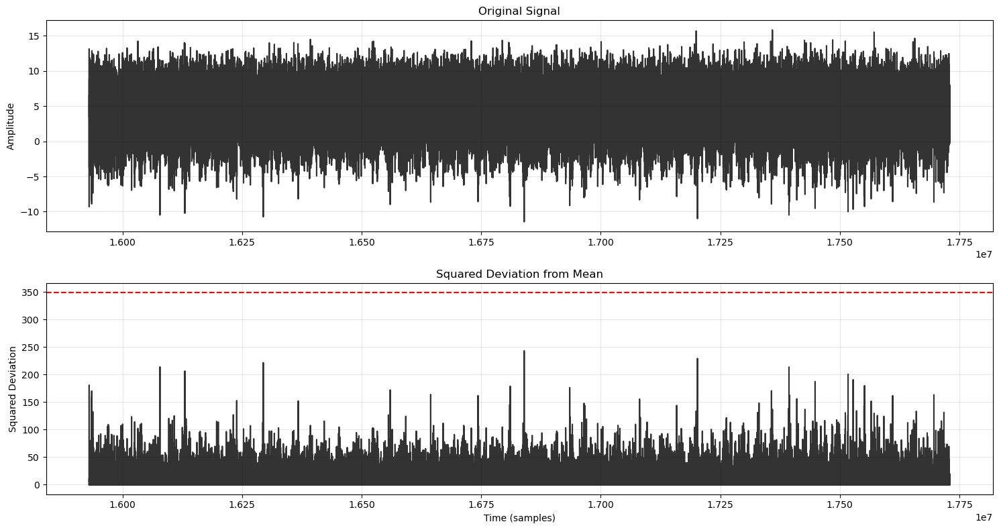

Processing samples 17700160 to 19500176
1800016
1800016


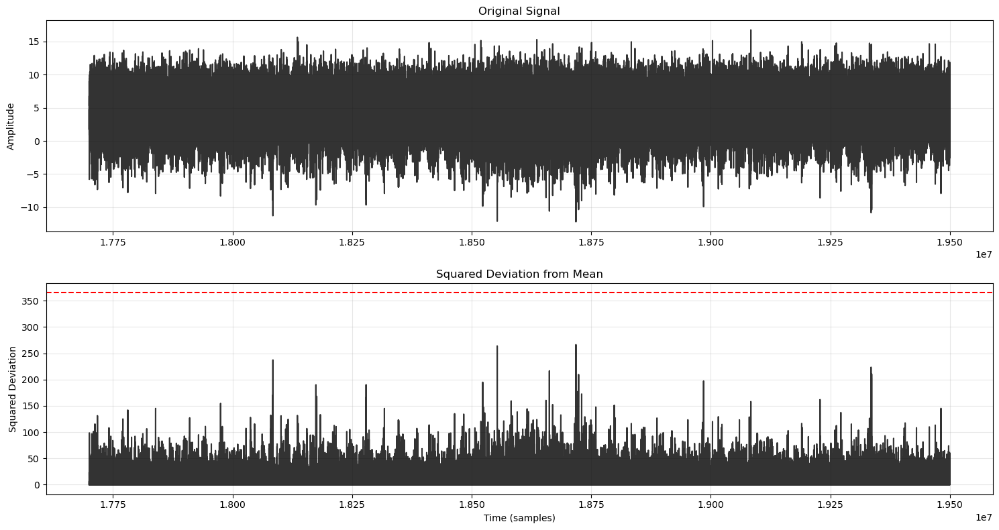

Processing samples 19470176 to 21270192
1800016
1800016


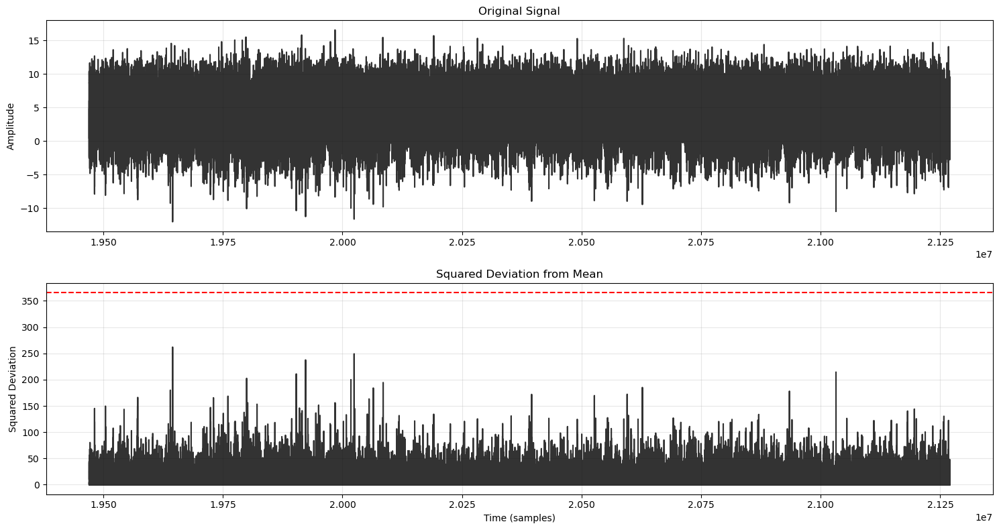

Processing samples 21240192 to 23040208
1800016
1800016


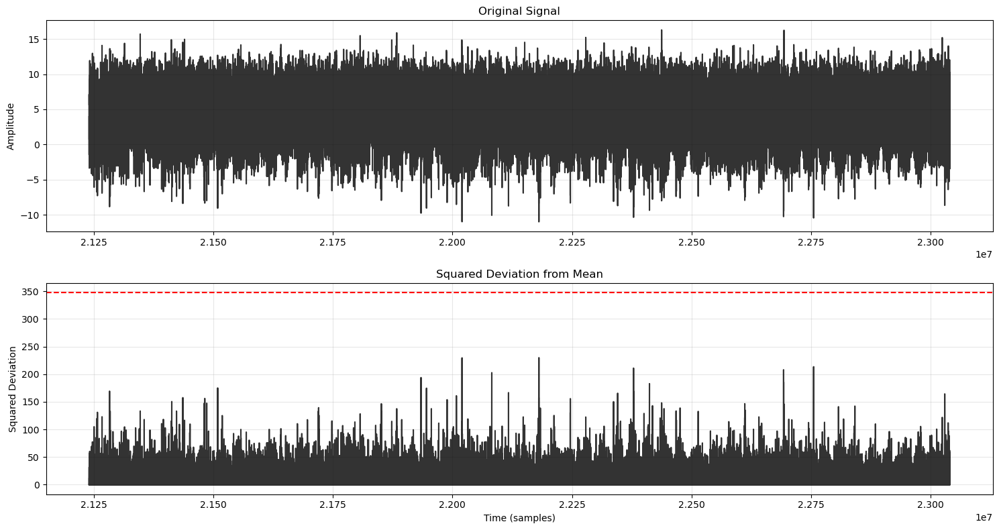

Processing samples 23010208 to 24810224
1800016
1800016
[]


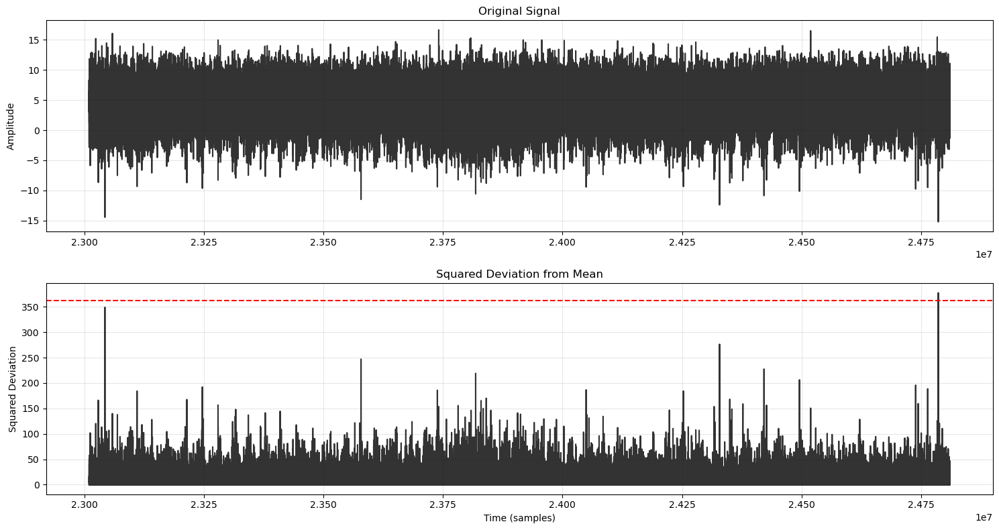

Processing samples 24780224 to 26580240
1800016
1800016
[]


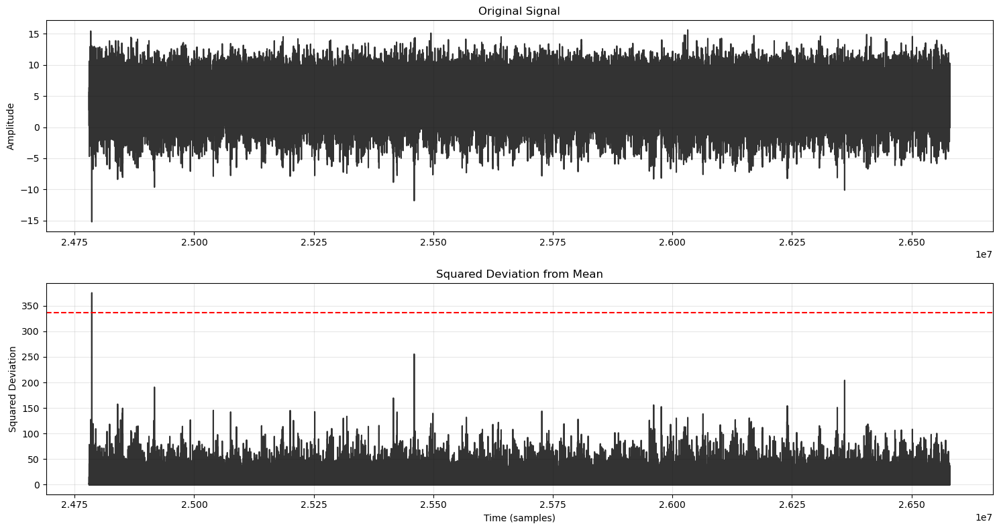

Processing samples 26550240 to 28350256
1800016
1800016
[27922771 27922772 27922773 27922774 27922775]


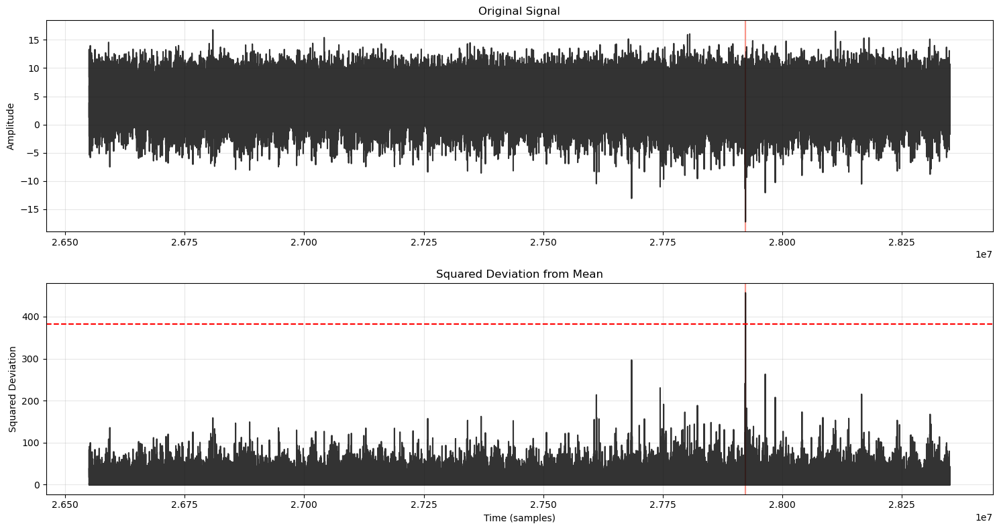

Processing samples 28320256 to 30120272
1800016
1800016


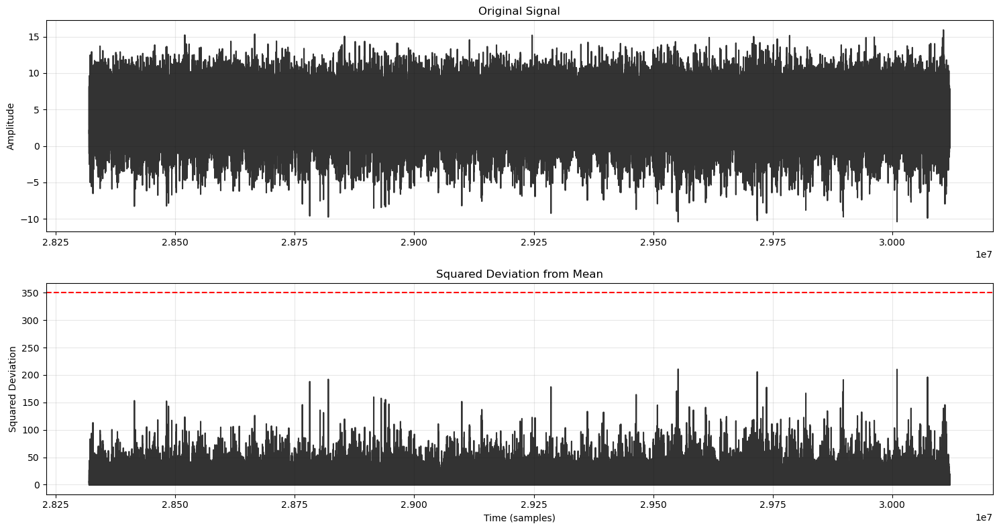

Processing samples 30090272 to 31890288
1800016
1800016


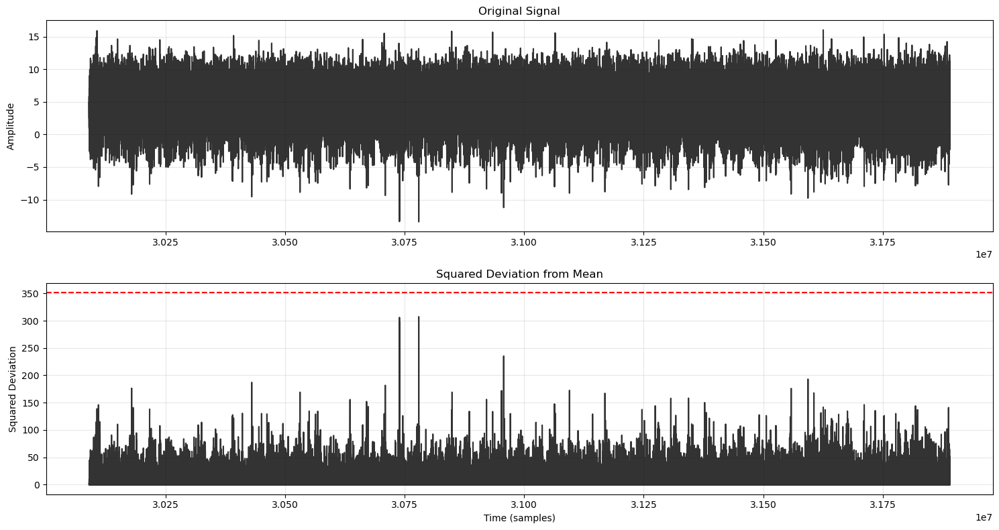

Processing samples 31860288 to 33660304
1800016
1800016


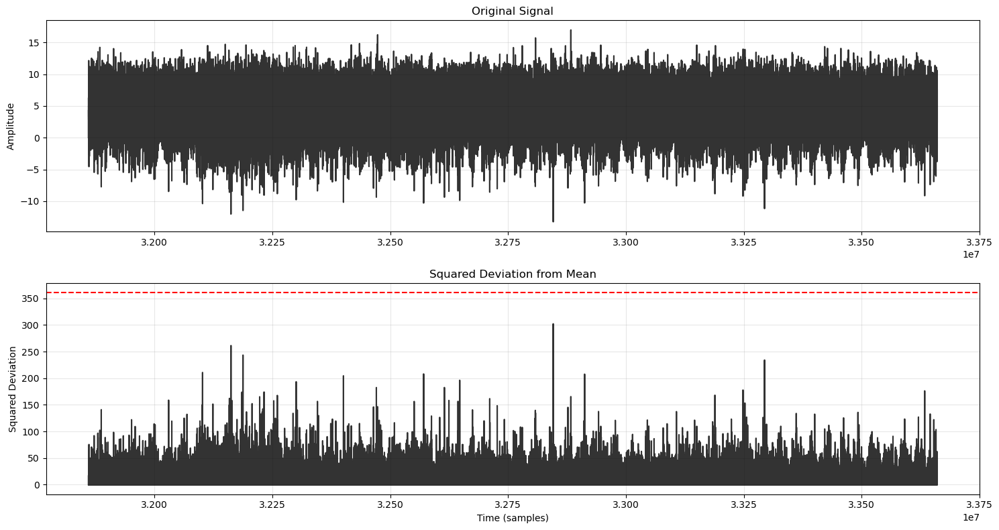

Processing samples 33630304 to 35430320
1800016
1800016


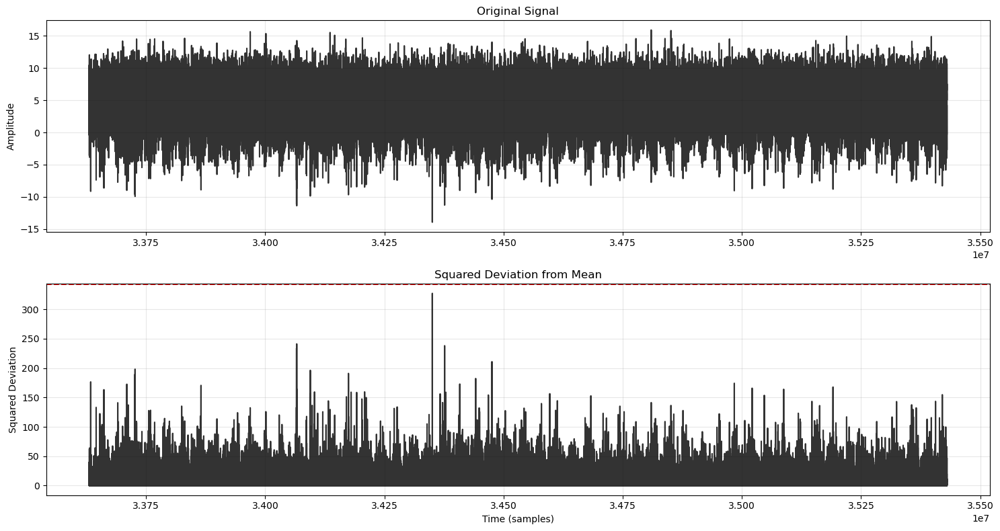

Processing samples 35400320 to 37200336
1800016
1800016


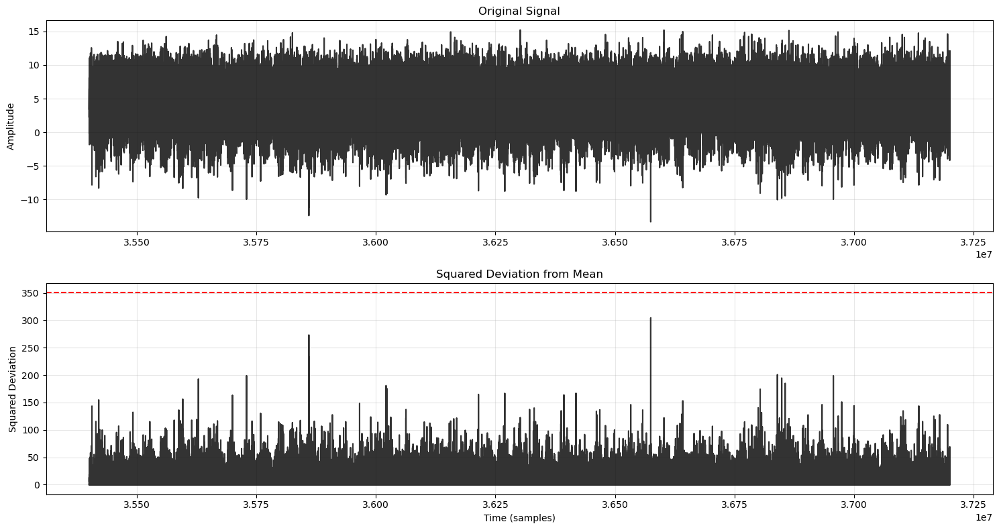

Processing samples 37170336 to 38970352
1800016
1800016
[]


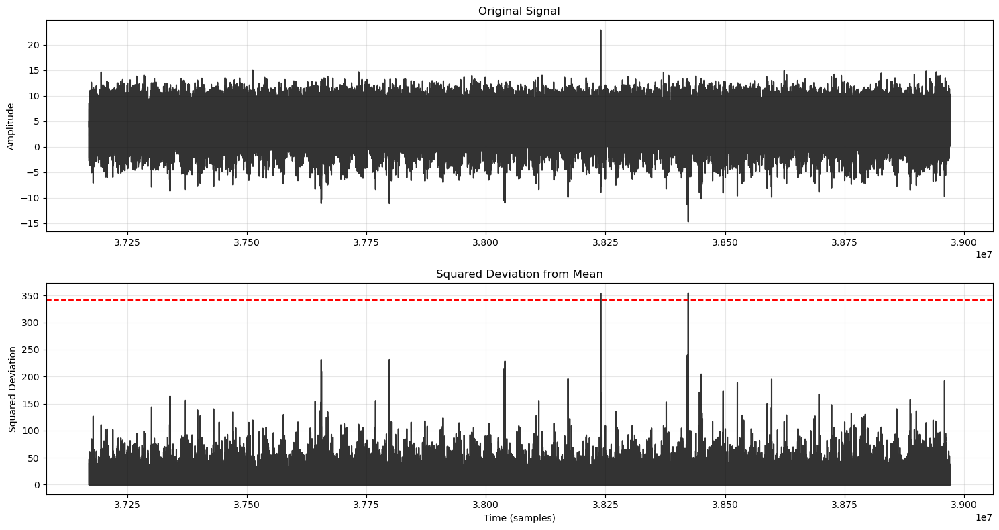

Processing samples 38940352 to 40740368
1800016
1800016


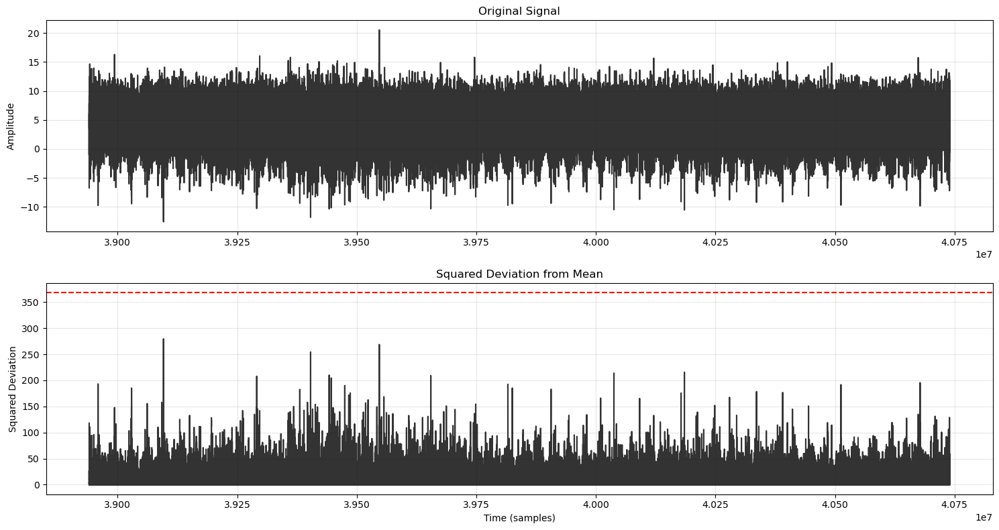

Processing samples 40710368 to 42510384
1800016
1800016


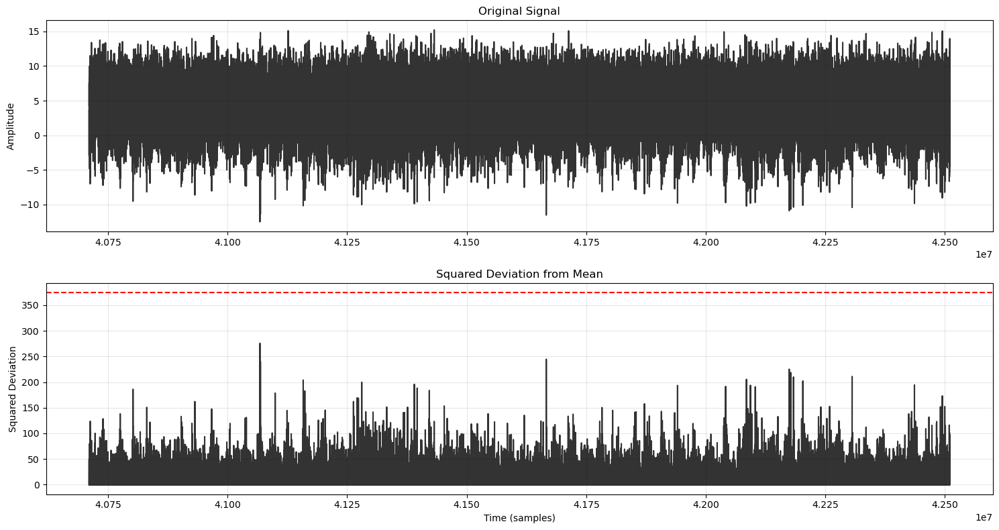

Processing samples 42480384 to 44280400
1800016
1800016


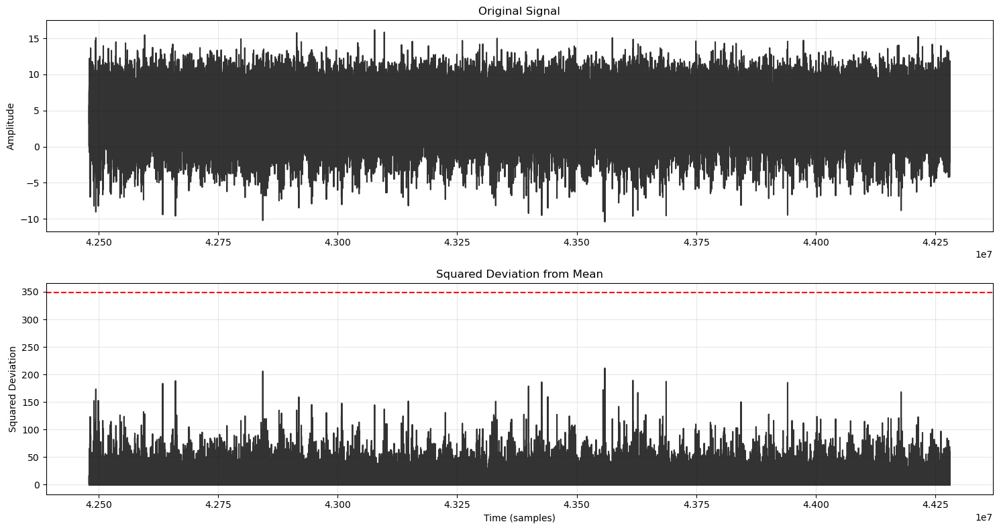

Processing samples 44250400 to 46050416
1800016
1800016


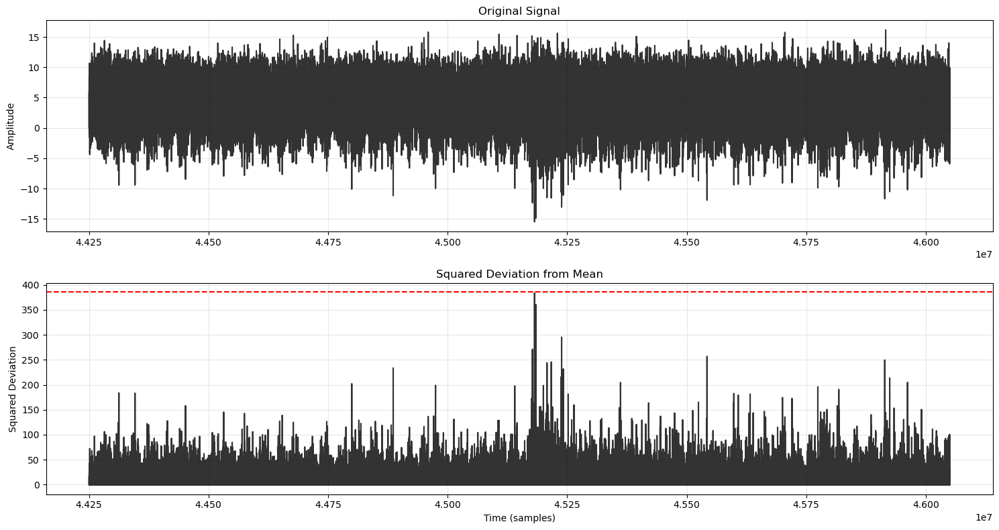

Processing samples 46020416 to 47820432
1800016
1800016


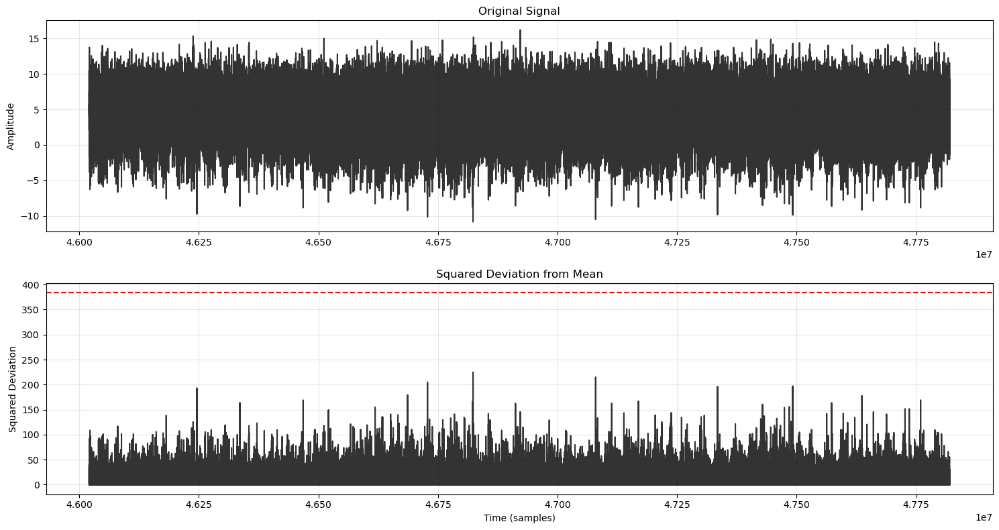

Processing samples 47790432 to 49590448
1800016
1800016
[49293883 49293884 49293885 49293886]


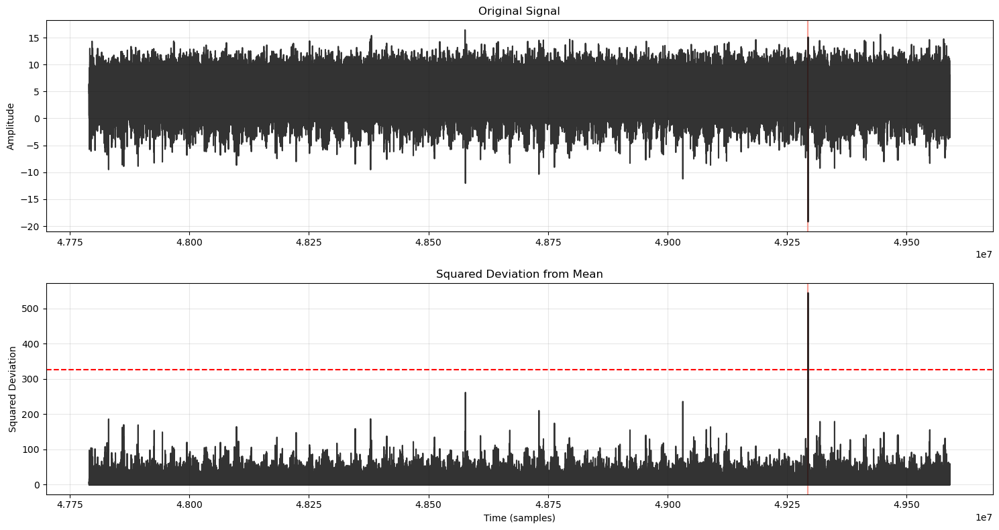

Processing samples 49560448 to 51360464
1800016
1800016


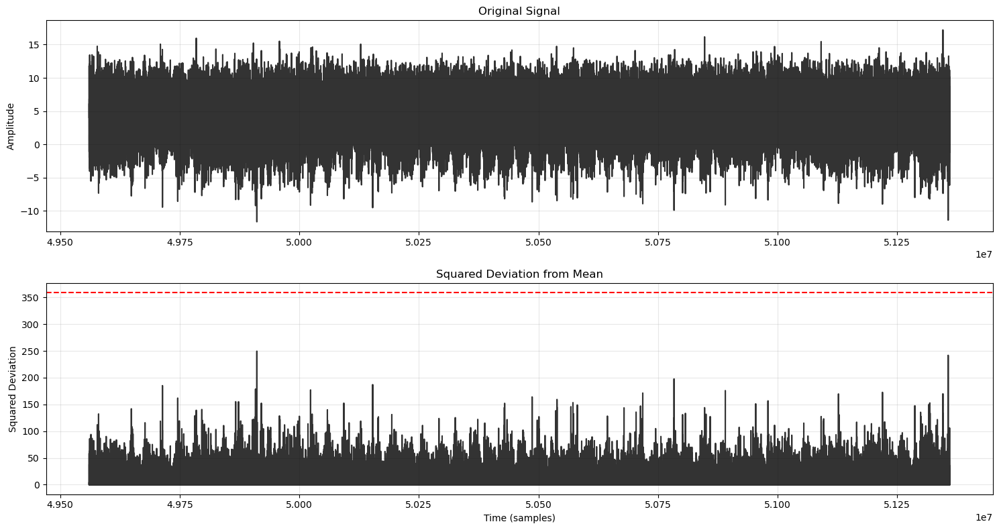

Processing samples 51330464 to 53130480
1800016
1800016


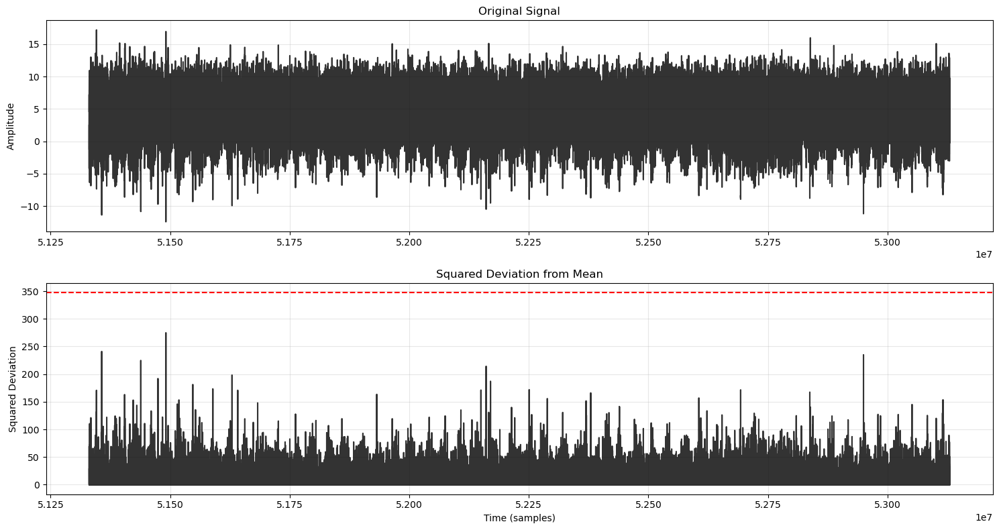

Processing samples 53100480 to 54900496
1800016
1800016


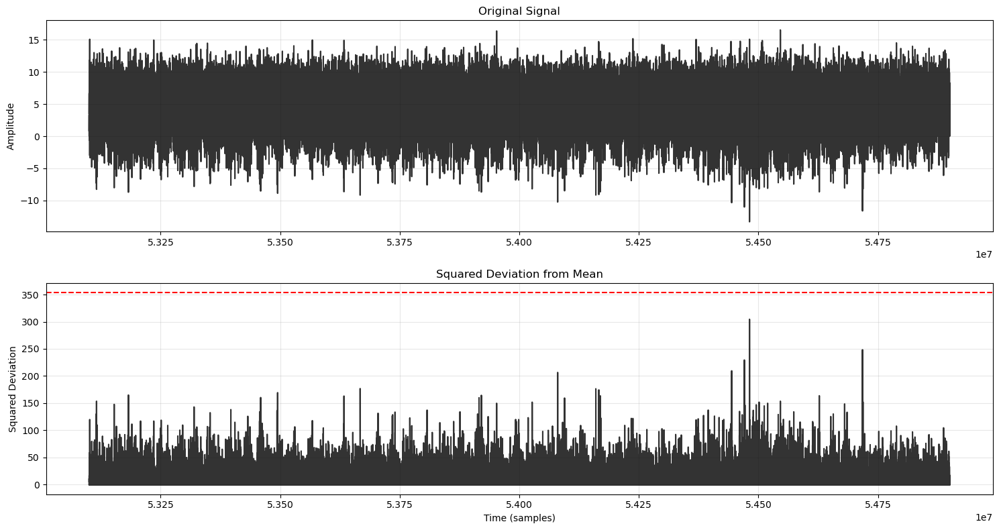

Processing samples 54870496 to 56670512
1800016
1800016


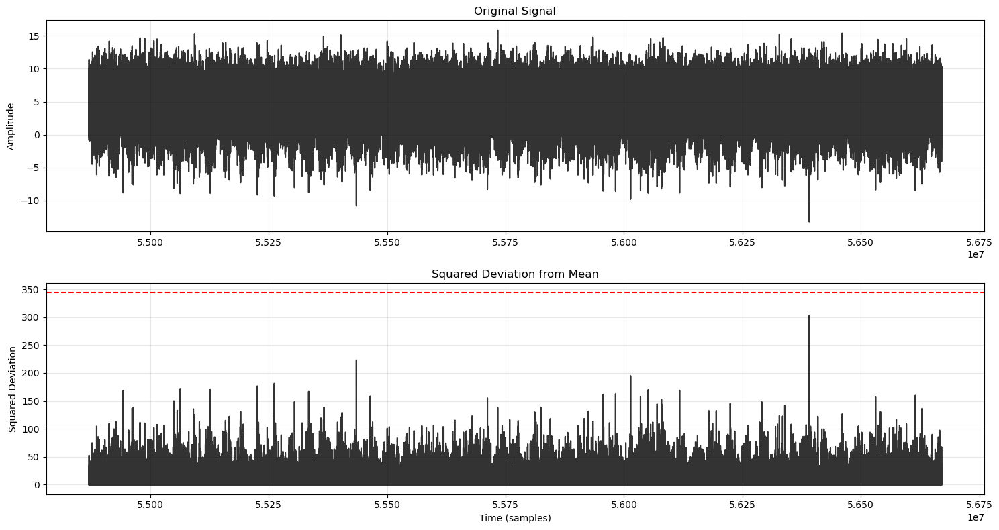

Processing samples 56640512 to 58440528
1800016
1800016
[58242485 58242486]


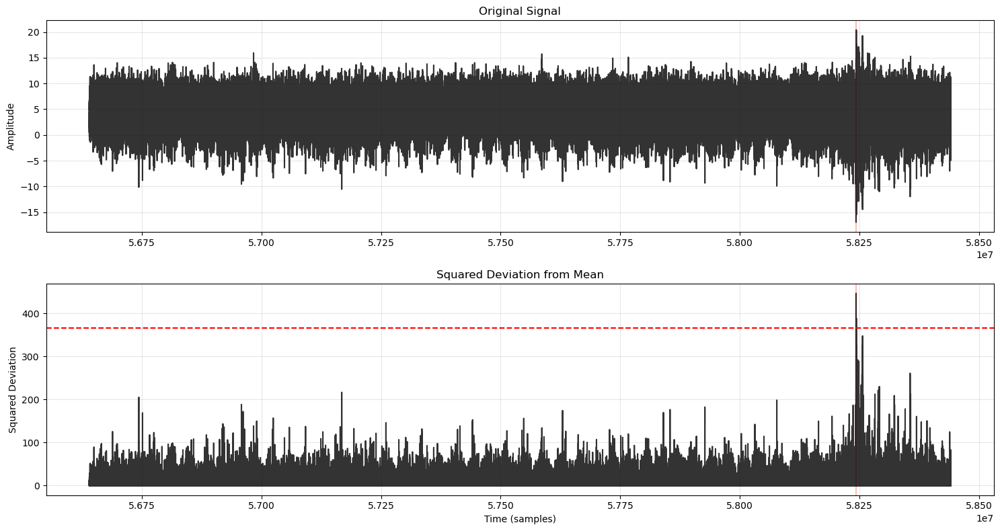

Processing samples 58410528 to 60210544
1800016
1800016


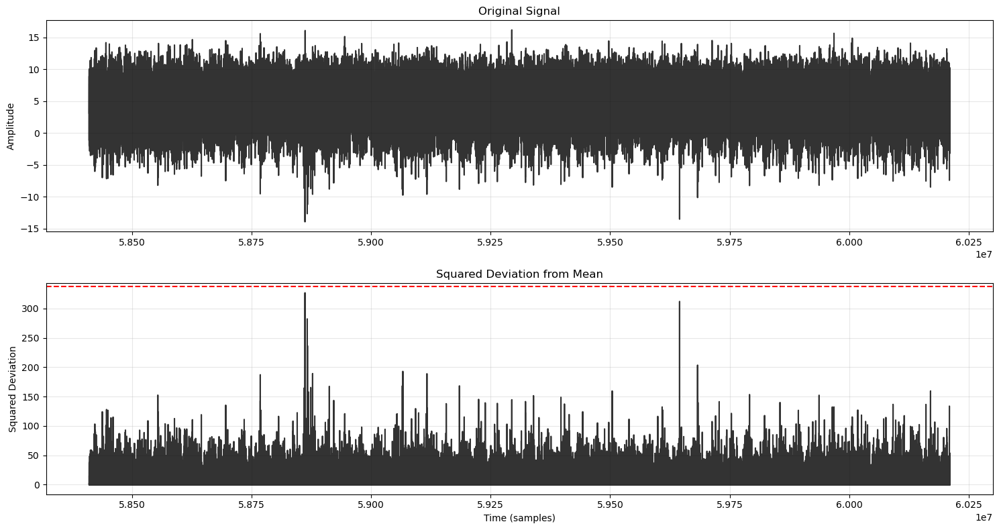

Processing samples 60180544 to 61980560
1800016
1800016


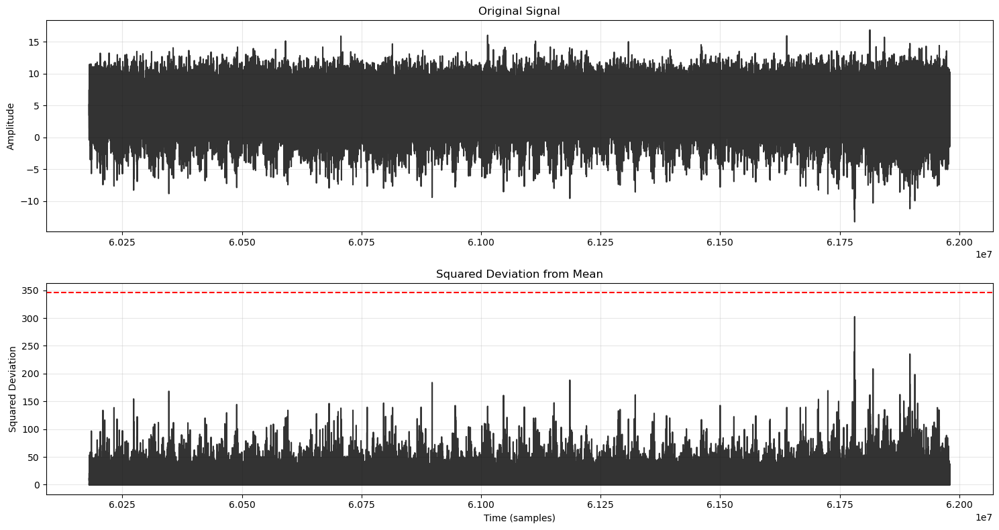

Processing samples 61950560 to 63750576
1800016
1800016


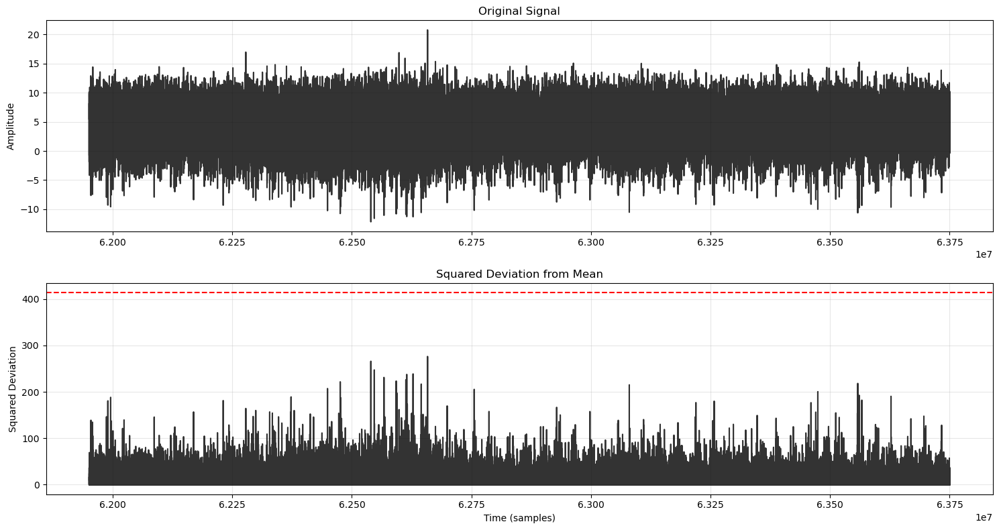

Processing samples 63720576 to 65520592
1800016
1800016


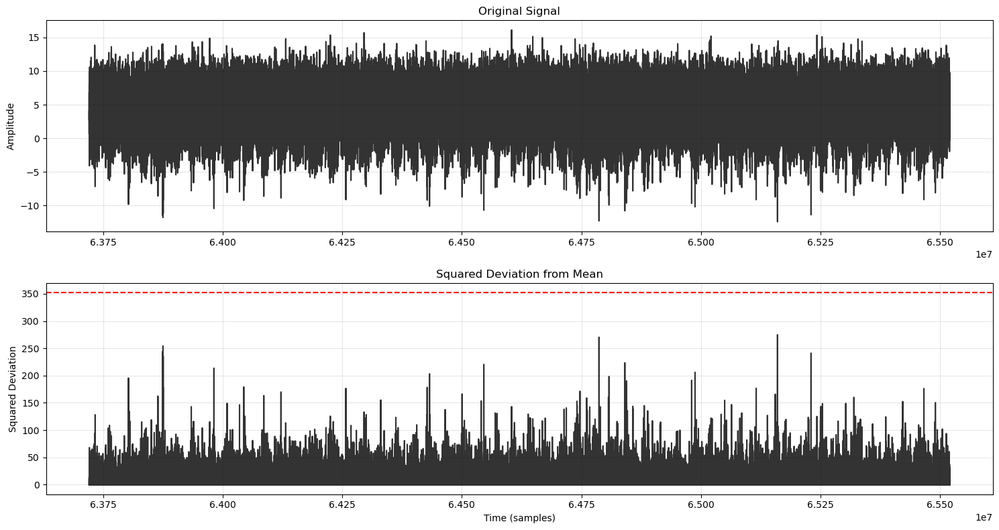

Processing samples 65490592 to 67290608
1800016
1800016


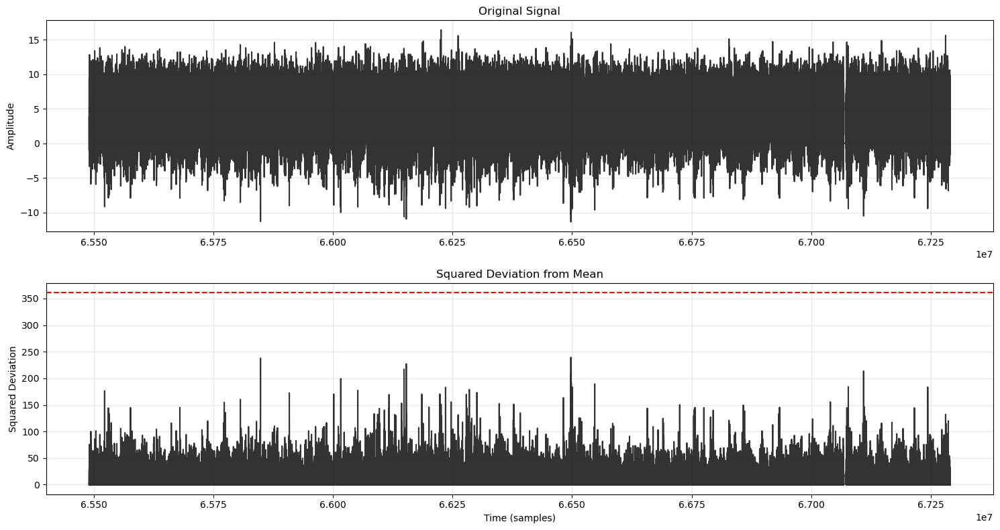

Processing samples 67260608 to 69060624
1800016
1800016


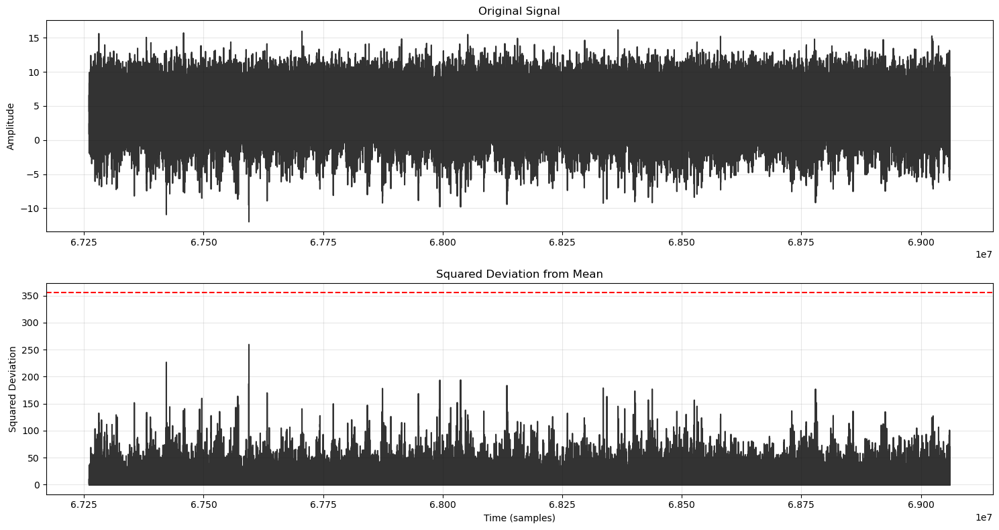

Processing samples 69030624 to 70830640
1800016
1800016
[69447316 69447317]


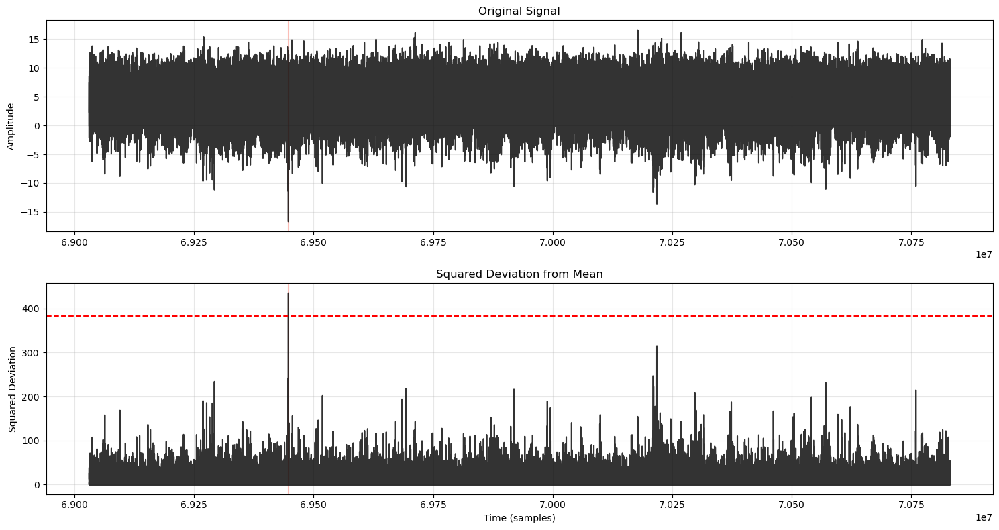

Processing samples 70800640 to 72600656
1800016
1800016


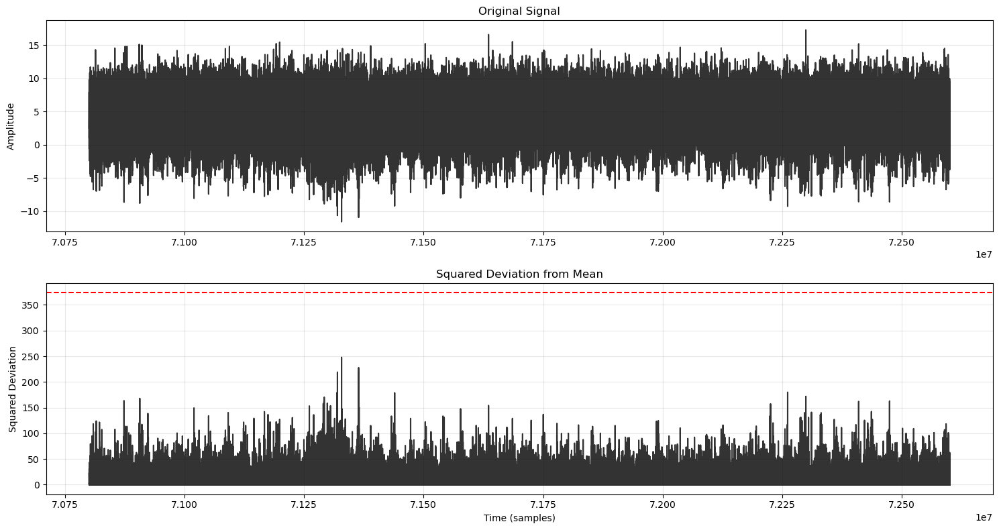

Processing samples 72570656 to 74370672
1800016
1800016
[72632697 72632698 72632699 72632700]


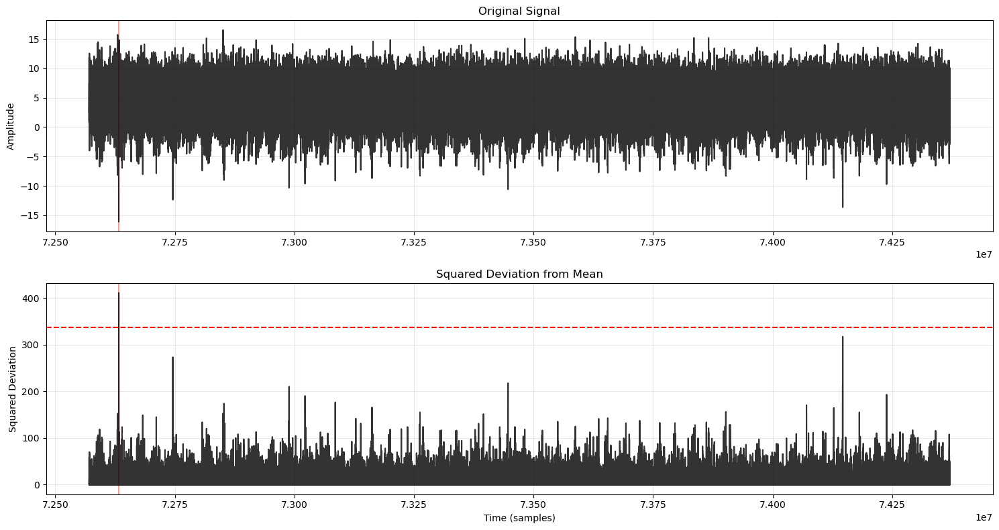

Processing samples 74340672 to 76140688
1800016
1800016


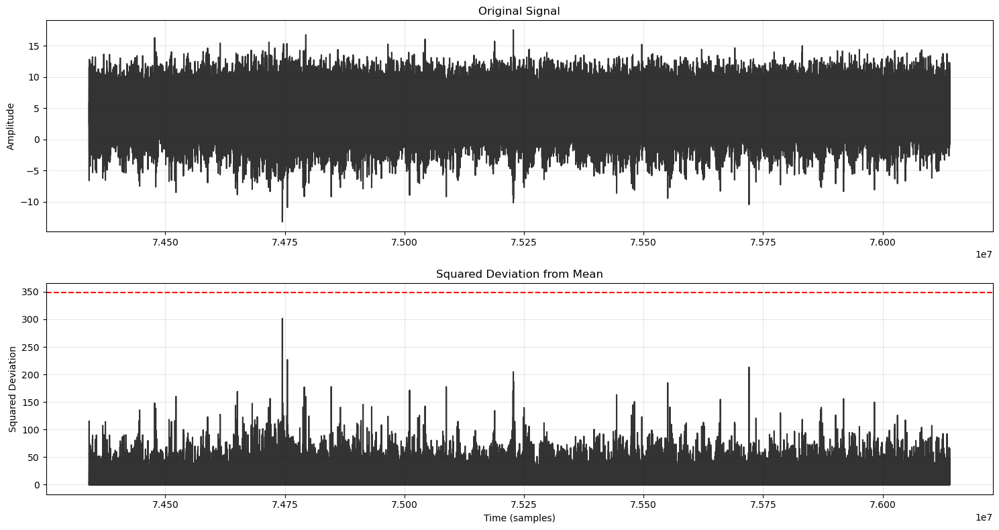

Processing samples 76110688 to 77910704
1800016
1800016


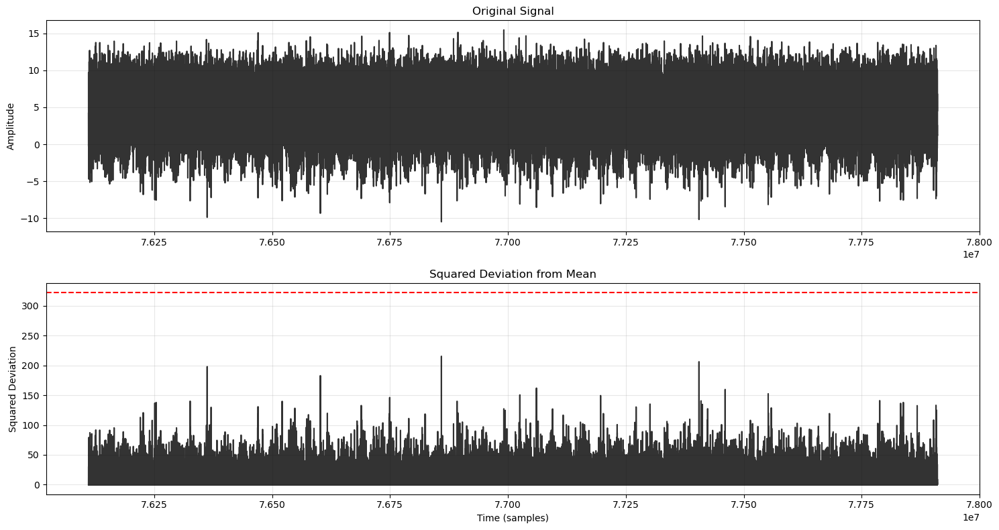

Processing samples 77880704 to 79680720
1800016
1800016


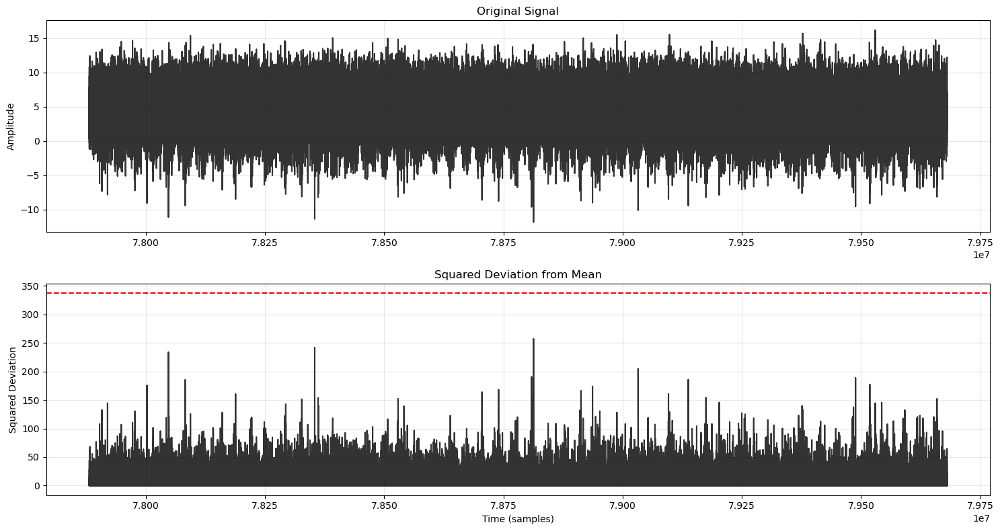

Processing samples 79650720 to 80418082
767362
767362


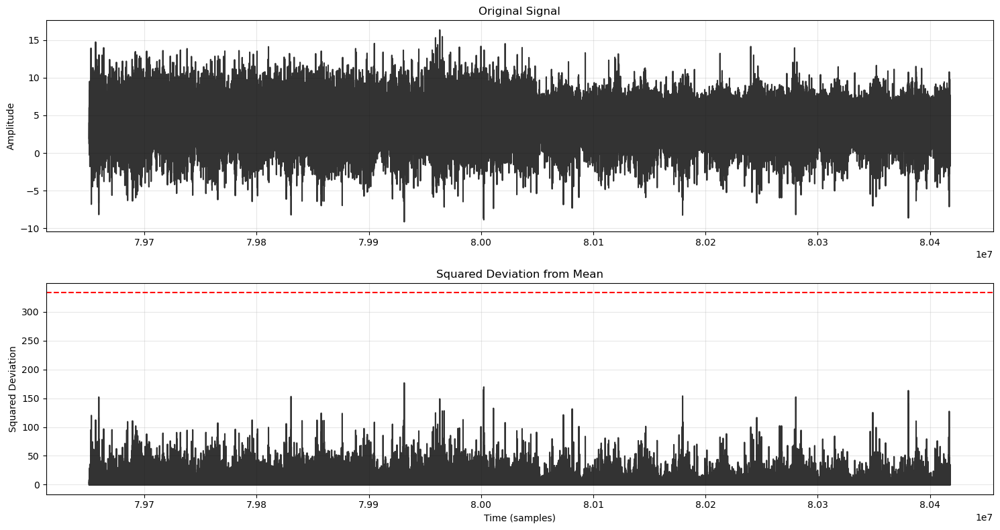

Artifact detection complete!


In [22]:
################ BY SQR DEVIATION ###################
rec1 = si.read_spikeglx(base_folder, stream_name='imec0.ap', load_sync_channel=False)

save_folder = Path(os.path.join(base_folder, "artifact_plots_sqd", "detection"))
save_folder.mkdir(parents=True, exist_ok=True)

window_size_sec = 60
std_threshold = 700
overlap_sec = 1 #when scanning the entire trace, the next chunk has 1s overlap with the previous chunk ==> aoivd an artifact being split into 2 chunks 
total_samples = rec1.get_num_samples(segment_index=0)

window_size = int(window_size_sec * fs)-1
overlap_size = int(overlap_sec * fs)
step_size = window_size - overlap_size

print(f"Total samples: {total_samples}, analyzing in {window_size_sec}s windows")

outliers_list = []

for start_sample in tqdm(range(0, total_samples, step_size), desc="Scanning dataset by minute"):
    end_sample = min(start_sample + window_size, total_samples)
    print(f"Processing samples {start_sample} to {end_sample}")
    trace = rec1.get_traces(0, start_sample, end_sample)
    trace_mean = np.mean(trace, axis=1)    
    mean_val = np.mean(trace_mean)
    std_val = np.std(trace_mean)
    time = np.arange(len(trace_mean)) + start_sample
    print(len(time))

    p_low, p_high = np.percentile(trace_mean, [20, 80])
    mask = (trace_mean >= p_low) & (trace_mean <= p_high)
    mean_robust, std_robust = np.mean(trace_mean[mask]), np.std(trace_mean[mask])
    sq_dev = (trace_mean - mean_robust) ** 2
    print(len(sq_dev))
    sq_dev_robust = sq_dev[mask]
    thresh_sq = np.mean(sq_dev_robust) + std_threshold * np.std(sq_dev_robust)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8))
    ax1.plot(time, trace_mean, 'k-', alpha=0.8)
    ax1.set_title('Original Signal')
    ax1.set_ylabel('Amplitude')
    ax1.grid(True, alpha=0.3)

    ax2.plot(time, sq_dev, 'k-', alpha=0.8)
    ax2.axhline(thresh_sq, color='red', ls='--')
    ax2.set_title('Squared Deviation from Mean')
    ax2.set_ylabel('Squared Deviation')
    ax2.set_xlabel('Time (samples)')
    ax2.grid(True, alpha=0.3)
    
    outliers_sq_local = sq_dev > thresh_sq  # Local indices for plotting
    if np.any(outliers_sq_local): 
        outlier_indices_local = np.where(outliers_sq_local)[0]

        keep_mask = np.zeros_like(outlier_indices_local, dtype=bool)
        for i, idx in enumerate(outlier_indices_local):
            has_prev_neighbor = (i > 0) and (outlier_indices_local[i-1] == idx - 1)
            has_next_neighbor = (i < len(outlier_indices_local) - 1) and (outlier_indices_local[i+1] == idx + 1)
            if has_prev_neighbor or has_next_neighbor:
                keep_mask[i] = True
        filtered_indices = outlier_indices_local[keep_mask]

        outlier_indices_global = filtered_indices + start_sample
        print(outlier_indices_global)
        outliers_list.extend(outlier_indices_global.tolist())

        for idx in filtered_indices:
            ax1.axvline(x=idx + start_sample, color='salmon', alpha=0.3, zorder = 1)
            ax2.axvline(x=idx + start_sample, color='salmon', alpha=0.3, zorder = 1)

    plt.tight_layout()
    
    save_path = save_folder / f"artifact_{start_sample}_{end_sample}.png"
    plt.savefig(save_path)
    plt.show(fig)
    plt.close(fig)

print("Artifact detection complete!")


In [23]:
'''
print("eInkOn:", eInkOn)
print("eInkOff:", eInkOff)
'''
outliers_list = np.array(outliers_list) / fs 
print(outliers_list)

[ 139.48054848  139.48058181  243.60243112  243.60246446  392.19496015
  392.19499349  392.19502682  392.19506015  392.19509349  392.19512682
  930.7502371   930.75027044  930.75030377  930.7503371   930.75037044
 1643.11390478 1643.11393811 1643.11397144 1643.11400478 1941.39781912
 1941.39785246 2314.88865605 2314.88868938 2421.06701925 2421.06705259
 2421.06708592 2421.06711925]


In [24]:
input_name = "overview"
def save_array(arr, label):
    filename = f"{label}_{input_name}.txt"
    save_path = os.path.join(base_folder, filename)
    with open(save_path, "w") as f:
        f.write(",".join(map(str, arr)))

save_array(outliers_list, "outliers_list_sqr")


In [25]:
#### if triggers already known ## 
outliers_list = np.loadtxt(os.path.join(base_folder, "outliers_list_sqr_overview.txt"), delimiter=',')
#####

#print(eInkOff - eInkOn)
list_triggers = outliers_list
print(list_triggers)
list_triggers_samp = list_triggers*fs
print(len(list_triggers))

ms_before = 150
ms_after = 150
rec_clean = si.remove_artifacts(recording=rec, list_triggers=list_triggers_samp, mode='zeros',ms_before=ms_before,ms_after = ms_after)

[ 139.48054848  139.48058181  243.60243112  243.60246446  392.19496015
  392.19499349  392.19502682  392.19506015  392.19509349  392.19512682
  930.7502371   930.75027044  930.75030377  930.7503371   930.75037044
 1643.11390478 1643.11393811 1643.11397144 1643.11400478 1941.39781912
 1941.39785246 2314.88865605 2314.88868938 2421.06701925 2421.06705259
 2421.06708592 2421.06711925]
27


In [26]:
####### SWEEP ACROSS THE WHOLE DATASET - CHECK IF ALL ARTIFACTS ARE REMOVED ###########
rec1 = si.read_spikeglx(base_folder, stream_name='imec0.ap', load_sync_channel=False)

save_folder = Path(os.path.join(base_folder, "artifact_plots_sqd", "confirmation"))
save_folder.mkdir(parents=True, exist_ok=True)

window_size_sec = 20
threshold_std = 1.5
percent_outliers_threshold = 11
overlap_sec = 1 #when scanning the entire trace, the next chunk has 1s overlap with the previous chunk ==> aoivd an artifact being split into 2 chunks 
total_samples = rec1.get_num_samples(segment_index=0)

window_size = int(window_size_sec * fs)-1
overlap_size = int(overlap_sec * fs)
step_size = window_size - overlap_size

print(f"Total samples: {total_samples}, analyzing in {window_size_sec}s windows")

close_artifact_segments = []  # store sample ranges where space_to_prev <400 for 5 consecutive times

rec_clean_astype = rec_clean.astype('float16')

remaining_outliers = []
for start_sample in tqdm(range(0, total_samples, step_size), desc="Scanning dataset by minute"):
    end_sample = min(start_sample + window_size, total_samples)
    trace = rec1.get_traces(0, start_sample, end_sample)
    trace_mean = np.mean(trace, axis=1)
    mean_val = np.mean(trace_mean)
    std_val = np.std(trace_mean)
    upper_threshold = mean_val + threshold_std * std_val
    lower_threshold = mean_val - threshold_std * std_val
    outlier_indices = np.where((trace_mean > upper_threshold) | (trace_mean < lower_threshold))[0]
    percent_outliers = (len(outlier_indices) / len(trace_mean)) * 100
    print(f"Chunk {start_sample}–{end_sample}: {percent_outliers:.2f}% of samples exceed threshold")

    if percent_outliers < percent_outliers_threshold: # this filters out chunks where std is small with no huge outliers ==> a lot of samples are above threshold  
        clean_trace = rec_clean_astype.get_traces(0, start_sample, end_sample)
        clean_trace_mean = np.mean(clean_trace, axis=1)
        clean_mean_val = np.mean(clean_trace_mean)
        clean_std_val = np.std(clean_trace_mean)
        clean_upper_threshold = clean_mean_val + threshold_std * clean_std_val
        clean_lower_threshold = clean_mean_val - threshold_std * clean_std_val
        clean_outlier_indices = np.where((clean_trace_mean > clean_upper_threshold) | (clean_trace_mean < clean_lower_threshold))[0]
        clean_percent_outliers = (len(clean_outlier_indices) / len(clean_trace_mean)) * 100
        
        if clean_percent_outliers < percent_outliers_threshold and len(clean_outlier_indices) > 0: 
            remaining_outliers.append(clean_outlier_indices+start_sample) 
        print(f"Chunk {start_sample}–{end_sample}: {clean_percent_outliers:.2f}% of samples exceed threshold")
        
        x = np.arange(start_sample, end_sample) / fs
        fig, (ax, ay) = plt.subplots(nrows=2, ncols=1, figsize=(20, 6), sharey=True)
        ax.plot(x, trace_mean[:], color='black')
        ax.set_title('Original Trace')
        ay.plot(x, clean_trace_mean[:], color='black')
        ay.set_title('Clean Trace')
        zero_mask = (clean_trace_mean == 0)
        if np.any(zero_mask):
            ay.scatter(x[zero_mask], clean_trace_mean[zero_mask], color='red', s=10, label='Zeroed samples')
            
        save_path = save_folder / f"artifact_{start_sample}_{end_sample}.png"
        plt.savefig(save_path)
        plt.show(fig)
        plt.close(fig)

Total samples: 80418082, analyzing in 20s windows


Scanning dataset by minute:   0%|          | 0/142 [00:00<?, ?it/s]

Chunk 0–600004: 11.50% of samples exceed threshold
Chunk 570004–1170008: 11.45% of samples exceed threshold
Chunk 1140008–1740012: 11.55% of samples exceed threshold
Chunk 1710012–2310016: 11.48% of samples exceed threshold
Chunk 2280016–2880020: 11.44% of samples exceed threshold
Chunk 2850020–3450024: 11.57% of samples exceed threshold
Chunk 3420024–4020028: 11.33% of samples exceed threshold
Chunk 3990028–4590032: 11.48% of samples exceed threshold
Chunk 4560032–5160036: 11.56% of samples exceed threshold
Chunk 5130036–5730040: 11.35% of samples exceed threshold
Chunk 5700040–6300044: 11.59% of samples exceed threshold
Chunk 6270044–6870048: 11.57% of samples exceed threshold
Chunk 6840048–7440052: 11.65% of samples exceed threshold
Chunk 7410052–8010056: 11.74% of samples exceed threshold
Chunk 7980056–8580060: 11.55% of samples exceed threshold
Chunk 8550060–9150064: 11.46% of samples exceed threshold
Chunk 9120064–9720068: 11.48% of samples exceed threshold
Chunk 9690068–10290072

In [27]:
print(remaining_outliers)
'''
if len(remaining_outliers) > 0: 
    raise Exception("There may be remaining outliers in the cleaned trace. please check manually!")
'''

[]


'\nif len(remaining_outliers) > 0: \n    raise Exception("There may be remaining outliers in the cleaned trace. please check manually!")\n'

In [28]:
###################################################

In [28]:
rec = rec_clean

In [29]:
chunks = si.get_random_data_chunks(rec,  num_chunks_per_segment=100, seed=0)
chunks.shape

(1500000, 355)

Saved channel std plot to /u/gongt/GLC6962_g_g0/processed_channel_std.png


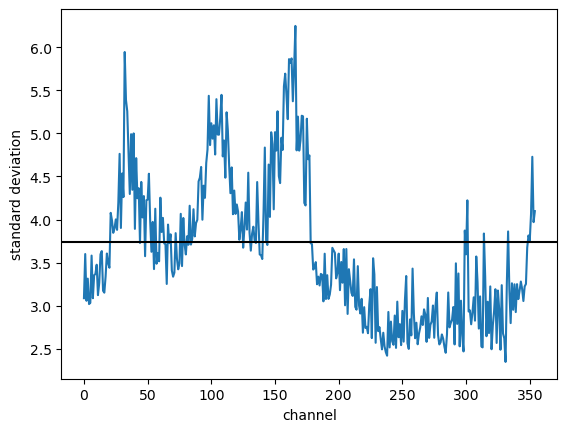

In [30]:
std = chunks.std(0)
gstd = chunks.std()
plt.plot(std)
plt.axhline(gstd, color='k')
plt.xlabel('channel')
plt.ylabel('standard deviation')

save_path = os.path.join(base_folder, "processed_channel_std.png")
plt.savefig(save_path, bbox_inches = 'tight')
print(f"Saved channel std plot to {save_path}")
plt.show(fig)
plt.close(fig)

In [31]:
rec = si.scale(rec, gain=1.0 / gstd, dtype='float16')

In [32]:
n_seconds = rec.get_duration()
n_mins = n_seconds / 60
chlen = 512
t_start = rec.get_start_time()
min_start = int(np.ceil(t_start / 60))

Created folder /u/gongt/GLC6962_g_g0/processed_neural_data for saving images
1577571


/tmp/ipykernel_113710/2103686321.py:17: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  chunk0 = rechp.get_traces(0, sample_start, sample_end, return_scaled=True)


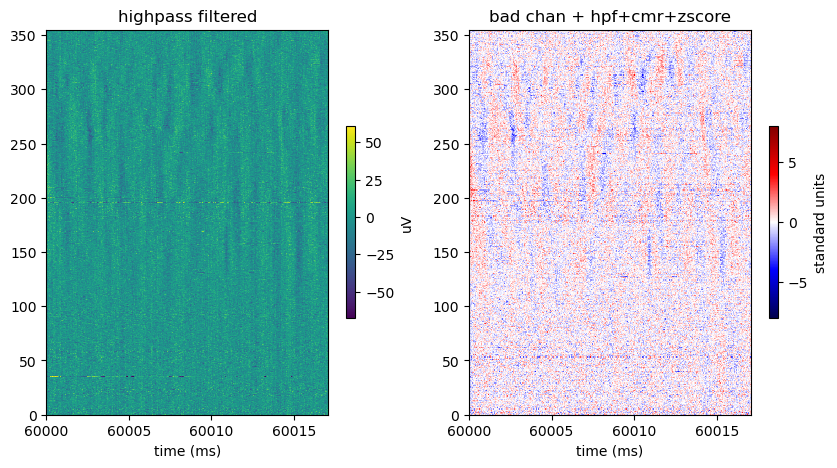

10577656


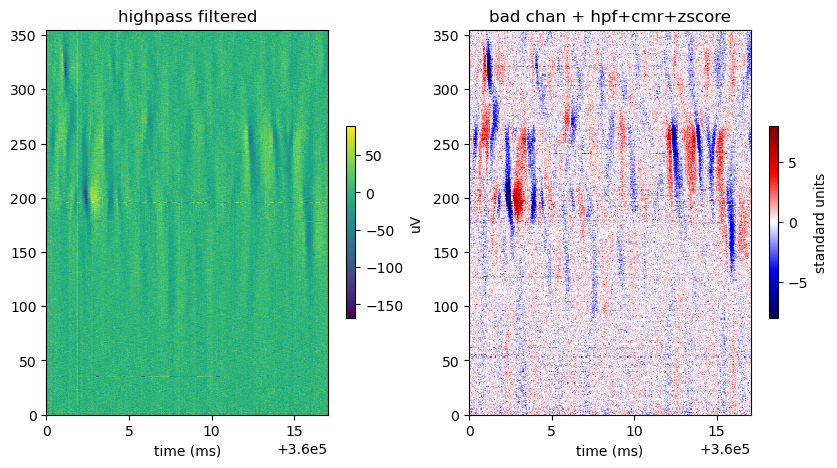

19577741


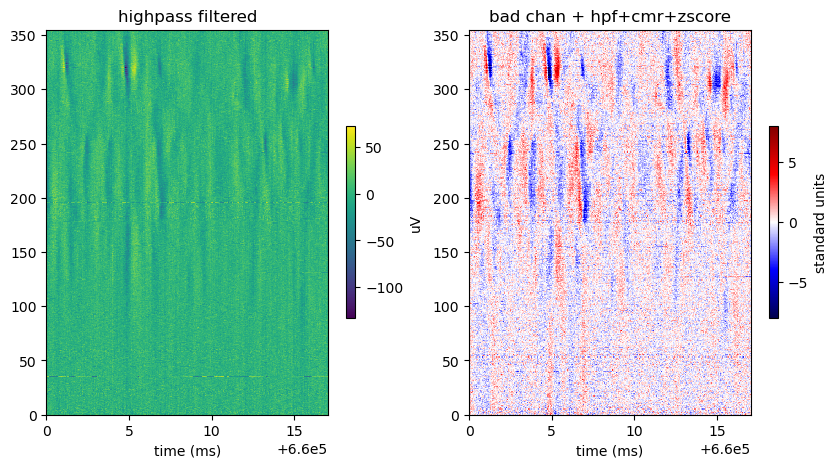

28577826


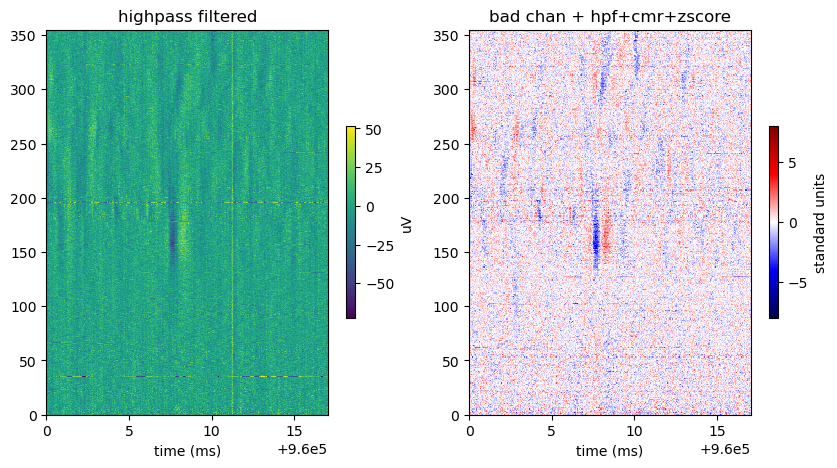

37577911


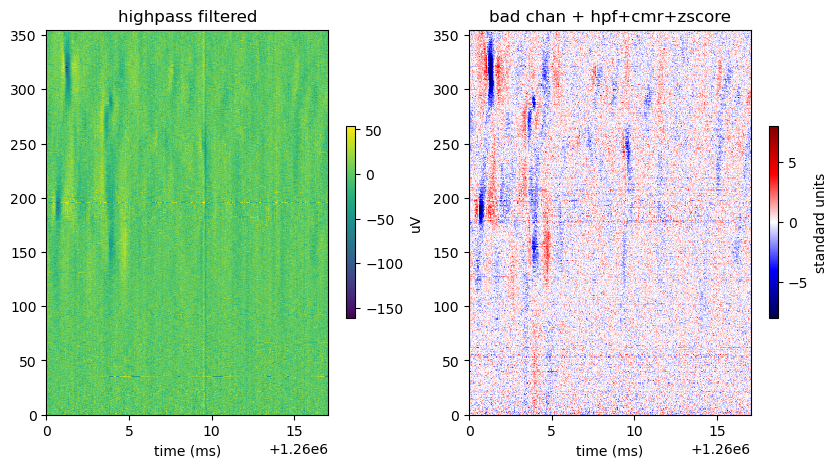

46577996


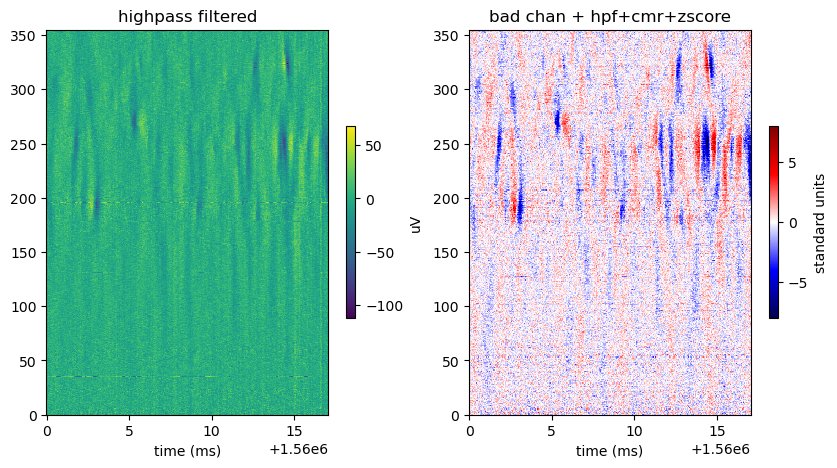

55578081


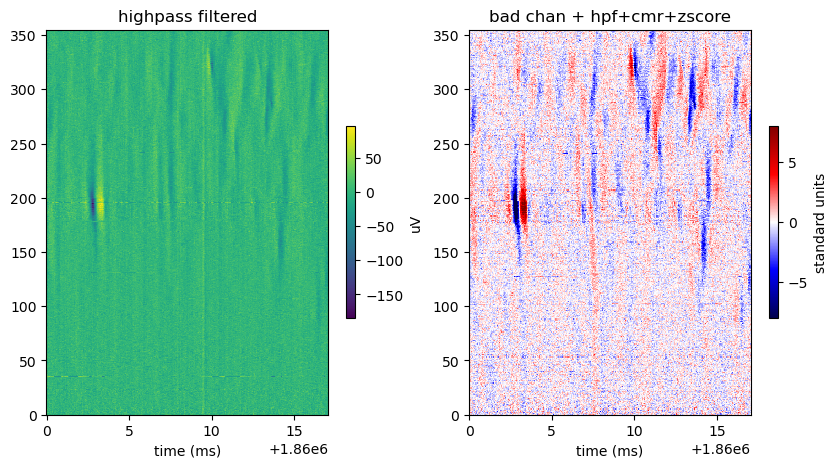

64578166


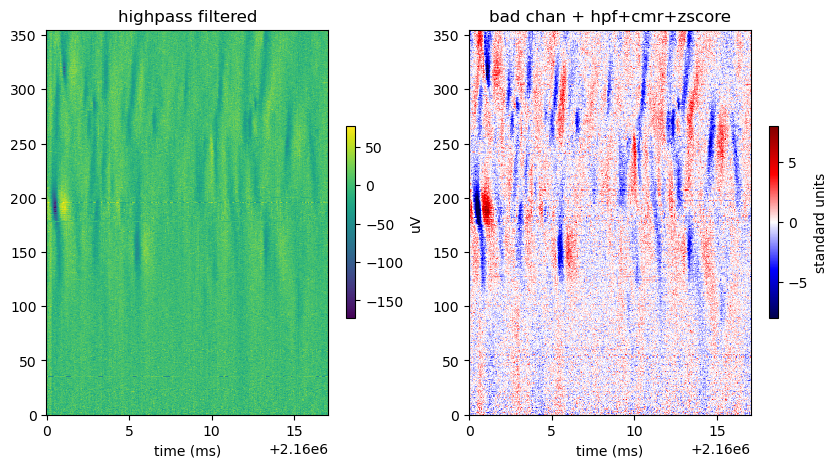

73578251


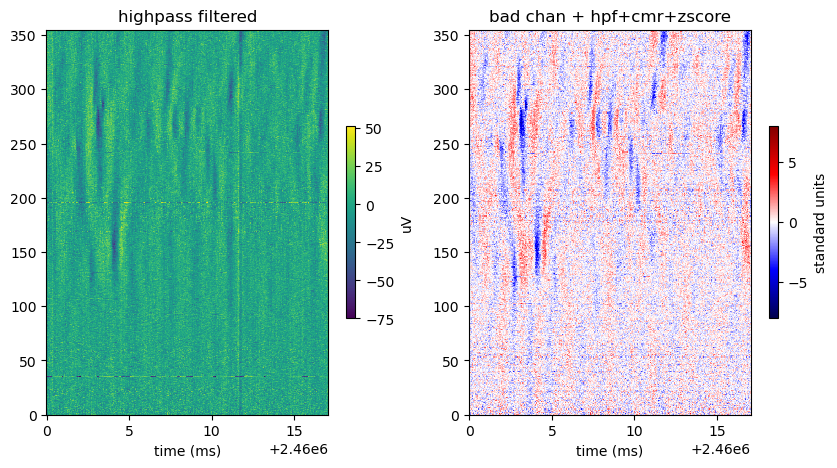

all plots successfully saved


In [33]:
save_folder = os.path.join(base_folder, "processed_neural_data")

if not os.path.exists(save_folder) or len(os.listdir(save_folder)) == 0:
    os.makedirs(save_folder, exist_ok=True)
    print(f"Created folder {save_folder} for saving images")
    imkw0 = dict(aspect='auto', interpolation='none', cmap='viridis')
    imkw = dict(aspect='auto', interpolation='none', cmap='seismic', vmin=-8, vmax=8)
    rechp = si.highpass_filter(si.read_spikeglx(rec_dir, stream_name='imec0.ap', load_sync_channel=False))

    for min_start in range(min_start, min_start + int(n_mins), 5):
        sample_start = rec.time_to_sample_index(min_start * 60)
        sample_end = sample_start + chlen
        t_start = rec.sample_index_to_time(sample_start) * 1000
        t_end = rec.sample_index_to_time(sample_end) * 1000
        print(sample_start)

        chunk0 = rechp.get_traces(0, sample_start, sample_end, return_scaled=True)
        chunk = rec.get_traces(0, sample_start, sample_end)

        fig, (ax, ay) = plt.subplots(ncols=2, figsize=(10, 5))

        im = ax.imshow(chunk0.T, extent=(t_start, t_end, 0, rec.get_num_channels()), **imkw0)
        plt.colorbar(im, ax=ax, shrink=0.5, label='uV')

        im = ay.imshow(chunk.T, extent=(t_start, t_end, 0, rec.get_num_channels()), **imkw)
        plt.colorbar(im, ax=ay, shrink=0.5, label='standard units')

        ax.set_title('highpass filtered')
        ay.set_title('bad chan + hpf+cmr+zscore')
        ax.set_xlabel("time (ms)")
        ay.set_xlabel("time (ms)")

        save_path = os.path.join(save_folder, f"segment_{min_start}min.png")
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show(fig)
        plt.close(fig)
        
    print("all plots successfully saved")
else: 
    print(f"Folder {save_folder} already exists and is not empty. Skip saving images.")

In [34]:
rec = rec.astype('float16')

In [35]:
rec

astype (AstypeRecording): 355 channels - 30000.283521 Hz - 1 segments - 80,418,082 samples 
        2,680.58s (44.68 minutes) - float16 dtype - 53.18 GiB

In [36]:
rec.save_to_folder(os.path.join(base_folder, "preprocessed"), overwrite=True, n_jobs=8)

Use cache_folder=/u/gongt/GLC6962_g_g0/preprocessed
write_binary_recording 
engine=process - n_jobs=8 - samples_per_chunk=30,000 - chunk_memory=20.31 MiB - total_memory=162.51 MiB - chunk_duration=1.00s (999.99 ms)


write_binary_recording (workers: 8 processes):   0%|          | 0/2681 [00:00<?, ?it/s]

BinaryFolderRecording: 355 channels - 30000.283521 Hz - 1 segments - 80,418,082 samples 
                       2,680.58s (44.68 minutes) - float16 dtype - 53.18 GiB